<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Marchiori2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ATTAQ: adversarial robustness of a quantum neural network (QFC) versus a classical network (CFC), step by step

This notebook re-implements, runs and checks the experiments of

> Francesco Marchiori and Mauro Conti,
> "ATTAQ: Adversarial Robustness of Quantum Machine Learning",
> 2025 55th Annual IEEE/IFIP International Conference on Dependable Systems and Networks Workshops (DSN-W), 2025.
> DOI 10.1109/DSN-W65791.2025.00062. Code: https://github.com/Mhackiori/ATTAQ

The authors' repository (pinned here to commit `b7b9818`) was read to recover the details the paper leaves out, but **the pipeline below is our
own code**: the paper's TorchQuantum model is rebuilt as an exact state-vector simulator in PyTorch, checked against a Qiskit circuit, and the
five attacks (FGSM, BIM, PGD, RFGSM, APGD) are re-written with the defaults of `torchattacks 3.5.1`, which the authors used.

**What the notebook does.** It downloads MNIST (digits 3 and 6), and, in the full run, Fashion-MNIST (dress vs shirt) and CIFAR-10 (cat vs dog,
grey, 28 x 28 crop). It trains the paper's two models, a **Quantum Fully Connected network (QFC)** (4 qubits, angle encoding of a 4 x 4 pooled image,
50 random RX/RY/RZ/CNOT gates plus trainable gates, Pauli-Z read-out) and a **Classical Fully Connected network (CFC)** (6 x 6 convolution and three
dense layers). It then repeats the paper's three studies:

1. **White-box attacks** (RQ1): attack success rate (ASR) of FGSM, BIM, PGD, RFGSM and APGD for the perturbation budget eps = 0.1 ... 1.0 (Fig. 3).
2. **Transferability** (RQ2): adversarial examples crafted on QFC are tested on CFC and the other way round (Table I). We add a Random Forest and an
   RBF-SVM, trained on the same 16 pooled inputs as the QFC, as extra classical targets.
3. **Adversarial training** (RQ3): both models are re-trained with adaptive online adversarial training whose eps grows from epoch to epoch (Fig. 4, Table II).

A final section sets every number the paper prints next to ours and gives a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs Qiskit (pinned) for the
circuit drawing; if Colab asks you to restart the session, do so and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed
(all three datasets are public; if you ever point the code at a gated dataset, add your own token under Colab *Secrets* as `HF_TOKEN`).

**Runtime.** `FAST_MODE = True` (MNIST only, a 2,500-image training sample, 5 epochs of batches of 64, 500 test images, one seed) takes about 10 to 15 minutes on a shared CPU (the adversarial training is the slowest part).
`FAST_MODE = False` follows the paper's budgets (all 10,844 training and 1,968 test images, 10 epochs, eps = 0.1 ... 1.0, three seeds, all three datasets);
it takes about 75 to 90 minutes on a shared single-thread CPU (adversarial training alone is about 45 minutes); the runtime is printed at the end.

**What you get at the end.** Trained models, ASR curves, the transferability and adversarial-training tables, the Qiskit drawing of the executed QFC
circuit, real-data scatter plots, a numerical equivalence check against `torchattacks`, and a table of paper-versus-notebook numbers.

## The paper in one page

**Problem.** Classical classifiers are fooled by tiny, deliberately chosen perturbations (*evasion attacks*, e.g. against intrusion detectors in
cybersecurity). Are quantum machine-learning (QML) models more or less vulnerable, do adversarial examples **transfer** between a quantum and a
classical model, and does **adversarial training** protect a quantum model?

**Decision.** Binary image classification: MNIST digits 3 vs 6, Fashion-MNIST dress vs shirt, CIFAR-10 cat vs dog (grey, 28 x 28 centre crop). The paper
analyses MNIST in detail ("we focus on the MNIST dataset"). The attack goal is to make a correctly classified test image be misclassified.

**Models** (both written with PyTorch): **QFC**, built with TorchQuantum: encoder `4x4_u3_h_rx` (a 28 x 28 image is average-pooled 6 x 6 to 4 x 4 = 16 numbers,
used as rotation angles of four qubits), 50 random gates (RX, RY, RZ, CNOT), trainable RX, RY, RZ, CRX, fixed H, SX, CNOT and RX(0.1), Pauli-Z read-out of
the four qubits, summed in pairs into two logits, log-softmax. **CFC**: 6 x 6 stride-6 convolution (4 channels), three dense layers with ReLU and dropout 0.3,
linear output, log-softmax. Adam (lr 5e-3, weight decay 1e-4), cosine schedule, 10 epochs, batch 256.

**Attacks** (`torchattacks`): FGSM, BIM, PGD, RFGSM and APGD (L-infinity), eps = 0.1, 0.2, ..., 1.0. Metric: **attack success rate** ASR (correctly classified
test images that are misclassified after the attack) and the accuracy drop.

**Claims we can test** (numbers are the paper's):

| Claim | Paper |
|---|---|
| Clean test accuracy on MNIST 3 vs 6, QFC / CFC (Sec. V-A) | 0.909 / 0.994 |
| White-box PGD ASR, QFC at eps = 0.5 / 1.0 (Sec. V-B) | 35.12 % / 45.19 % |
| White-box PGD ASR, CFC at eps = 0.5 / 1.0 (Sec. V-B) | 4.64 % / 10.15 % |
| Table I(a): ASR (%) mean over five attacks at eps = 0.3 / 0.5 / 1.0 | QFC->QFC 24.46 / 41.83 / 60.96; QFC->CFC 17.83 / 19.88 / 38.60; CFC->QFC 0.39 / 0.81 / 13.32; CFC->CFC 0.78 / 6.85 / 43.93 |
| Table I(b): accuracy drop (%), same setting | QFC->QFC 14.65 / 33.76 / 54.75; QFC->CFC 7.92 / 10.85 / 31.74; CFC->QFC -0.19 / 0.39 / 12.89; CFC->CFC 0.16 / 6.50 / 43.49 |
| RQ1: attacks are more effective on QFC than on CFC in the white-box setting | qualitative |
| RQ2: QFC->CFC transfers better than CFC->QFC | qualitative |
| Table II(a): ASR (%) after adversarial training | QFC->QFC 15.13 / 31.56 / 51.20; QFC->CFC 12.32 / 14.88 / 35.55; CFC->QFC 0.23 / 0.22 / 5.06; CFC->CFC 0.19 / 0.53 / 11.01 |
| Table II(b): accuracy drop (%) after adversarial training | QFC->QFC 7.89 / 24.68 / 46.36; QFC->CFC 4.30 / 7.11 / 29.34; CFC->QFC -0.40 / -0.31 / 4.85; CFC->CFC -0.39 / -0.13 / 10.18 |
| RQ3: adversarial training helps CFC a lot, QFC only marginally | qualitative |

Fig. 3 and Fig. 4 (ASR against eps) are printed without numbers; we redraw them and check their described shape.

## What follows the paper and what had to be chosen

The paper gives the architectures and the attack names; the released code settles most of the rest. Everything the paper and the code leave open is marked
`# CHOICE:` in the code.

| Item | Paper / released code | This notebook |
|---|---|---|
| Quantum framework | TorchQuantum (GPU-ready PyTorch simulator) | **own exact state-vector simulator in PyTorch** (TorchQuantum is not installed in Colab); gate list taken from the TorchQuantum source (commit `8dc3255`), then **asserted equal to a Qiskit circuit** (fidelity 1) |
| Random layer | `tq.RandomLayer(n_ops=50)` of RX/RY/RZ/CNOT; its random draw depends on an unseeded NumPy state | the same recipe, drawn from `np.random.default_rng(seed)`; **a different random circuit per seed** (so the seed spread includes the circuit) |
| Parameter initialisation | TorchQuantum default U(-pi, pi) | U(-pi, pi) |
| Data | TorchQuantum `MNIST`, `CIFAR10` loaders (torchvision downloads) | Hugging Face parquet mirrors (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, `uoft-cs/cifar10`), same pixel normalisation, same 90 / 10 train / validation split (`random_split` with generator seed 1) |
| Image range given to the attacks | images are **normalised** (mean 0.1307, std 0.3081) *and* `torchattacks` clamps its output to [0, 1] | **"released" mode copies this** (it is what produced the paper's numbers, as far as we can tell); a second **"valid range"** mode clamps to the true normalised pixel range [-0.42, 2.82] and is reported as a sensitivity study |
| Loss for the attacks | `nn.CrossEntropyLoss` on the model's log-softmax output | same (for a log-softmax output this equals the NLL loss) |
| Attack hyper-parameters | `torchattacks` defaults: PGD/BIM/RFGSM alpha = 2/255, 10 steps, PGD random start; APGD 10 steps, 1 restart | same defaults; **note** alpha = 2/255 caps BIM/PGD movement at about 0.08 per pixel whatever eps is |
| CFC output layer | `nn.Linear(4, 10)` + log-softmax for a 2-class task | kept (10 outputs, only two used) |
| ASR definition | text: relative to *all* test images; code: relative to the images the **evaluated** model classifies correctly | both are computed; the table uses the code's definition (`ASR`) and shows the text's (`ASR_all`) |
| Source / target naming | repository CSV columns are swapped (the "target" column holds the model that *crafted* the images) | "source" = model that crafts the images, "target" = model that is evaluated (the reading in the paper's text) |
| Adversarial training | 21 attacks per batch, one optimiser step per attack, eps = epoch / 10; "independent" and "joint" variants | **the paper's five attacks**, same schedule and update rule; independent variant only (the paper's footnote says the joint variant gives similar findings) |
| Evaluation after training | repository evaluates the adversarially trained models on the adversarial images pre-computed from the **undefended** models | both: *protocol A* (as released, undefended source) and *protocol B* (adaptive: the attack is re-run against the trained model) |
| Seeds, sample sizes | one seed (151836), all 10,844 / 1,968 images | `FAST_MODE`: small subsets, 1 seed; full: all images, 3 seeds (mean +- std) |
| Extra classical baselines | none | Random Forest and SVC(rbf) on the 16 pooled inputs of the QFC (clean accuracy and transfer targets) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, Pillow,
# pyarrow and huggingface_hub. Only Qiskit (circuit drawing + equivalence check) has to be added.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit already present; skipping pip install.")

Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE     = False         # True: class demo (about 10 minutes on a shared CPU). False: the paper's budgets (see the runtime note above).
SEED          = 42            # CHOICE: the paper's code uses 151836; we use 42 (and 43, 44 ... for further seeds)
DATA_DIR      = "data"        # cache for the downloaded parquet files (relative to the working directory)
IBM_TOKEN     = ""            # not used: the paper simulates everything; there is no hardware cell in this notebook
TORCH_THREADS = 1             # CPU threads for PyTorch (the 4-qubit simulator is made of tiny tensors: 1 thread is fastest, even on a shared machine)
CROSSCHECK_TORCHATTACKS = True   # compare our attacks with torchattacks 3.5.1 if it can be imported / installed

N_QUBITS      = 4             # the QFC has 4 qubits (fixed by the TorchQuantum model); 16 pooled pixels feed 4 rotations each
EPS_FULL      = [round(0.1 * i, 1) for i in range(1, 11)]       # paper: 0.1 ... 1.0
ATTACK_NAMES  = ["APGD", "BIM", "FGSM", "PGD", "RFGSM"]          # the paper's five main attacks
AT_ATTACKS    = ["APGD", "BIM", "FGSM", "PGD", "RFGSM"]          # CHOICE: the repository uses 21 attacks in adversarial training; we use these five
TABLE_EPS     = [0.3, 0.5, 1.0]                                  # eps values of Tables I and II

if FAST_MODE:
    DATASETS   = ["MNIST"]
    N_TRAIN, N_VALID, N_TEST = 2500, 300, 500      # CHOICE: paper uses 10,844 / 1,205 / 1,968 (all digit-3/6 images); smaller here for a quick demo
    EPOCHS     = 5                                 # paper: 10
    BS         = 64                                # CHOICE (FAST only): smaller batches give enough optimiser steps on a small sample; paper: 256
    N_SEEDS    = 1
    EPS_LIST   = [0.1, 0.3, 0.5, 0.8, 1.0]         # released mode, first seed
    EPS_OTHER  = EPS_VALID = EPS_AT = EPS_EXTRA = EPS_LIST
    MODES      = ["released", "valid"]
    RUN_AT     = True
    AT_SEEDS   = 1
else:
    DATASETS   = ["MNIST", "FashionMNIST", "CIFAR10"]
    N_TRAIN, N_VALID, N_TEST = None, None, None    # None = every image of the two chosen classes
    EPOCHS     = 10
    N_SEEDS    = 3
    EPS_LIST   = EPS_FULL                          # released mode, first seed: the paper's whole grid
    EPS_OTHER  = [0.3, 0.5, 1.0]                   # CHOICE (cost): released mode, seeds 2 and 3: only the eps values of Tables I/II and the PGD claims
    EPS_VALID  = [0.1, 0.3, 0.5, 0.8, 1.0]         # CHOICE (cost): "valid range" sensitivity study, first seed
    EPS_AT     = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]    # CHOICE (cost): attacks crafted on the adversarially trained models, first seed
    EPS_EXTRA  = [0.1, 0.3, 0.5, 1.0]              # Fashion-MNIST and CIFAR-10
    MODES      = ["released", "valid"]
    RUN_AT     = True
    AT_SEEDS   = 1                                 # adversarial training is the expensive part: first seed only
    BS         = 256
MAIN = "MNIST"                                     # the dataset the paper analyses in detail

In [3]:
import os, io, time, math, warnings, importlib.metadata as md
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")      # no progress-bar widgets in the saved outputs
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

# Hugging Face token: only needed for gated datasets. MNIST, Fashion-MNIST and CIFAR-10 are public, so an empty token is fine.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

matplotlib.rcParams["figure.dpi"] = 80                      # keeps the saved figures small
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.time()

print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| qiskit", md.version("qiskit"))
print("FAST_MODE =", FAST_MODE, "| datasets", DATASETS, "| epochs", EPOCHS, "| seeds", N_SEEDS, "| eps grid", EPS_LIST)

torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | qiskit 2.5.2
FAST_MODE = False | datasets ['MNIST', 'FashionMNIST', 'CIFAR10'] | epochs 10 | seeds 3 | eps grid [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 1. The datasets, downloaded and prepared

The paper uses three public image sets, each reduced to **two classes**: MNIST digits **3 and 6**, Fashion-MNIST **dress (3) and shirt (6)**, and CIFAR-10
**cat (3) and dog (5)**. The notebook downloads the official parquet files from the Hugging Face hub and caches them in `DATA_DIR`. It then follows the TorchQuantum
loaders used by the authors:

* pixels in [0, 1], then **standardised** with the dataset mean and standard deviation (MNIST and Fashion-MNIST: 0.1307 / 0.3081; CIFAR-10: grey-scale mean and std
  computed from the colour statistics, after the luma conversion and a 28 x 28 centre crop);
* the official training images of the two classes are split 90 % / 10 % into **training** and **validation** with a fixed random permutation; the official test
  images are the **test** set. Every model is fitted on the training split only, the validation split only monitors training, the test split is used for reporting.

Because the standardised pixel range is not [0, 1], the *valid* attack range is [(0 - mean) / std, (1 - mean) / std] = [-0.42, 2.82] for MNIST. `torchattacks` knows
nothing about this: it clamps to [0, 1]. Section 5 explains what that does.

In [4]:
# ---- 1.1 data: Hugging Face parquet mirrors, TorchQuantum's preprocessing and train/valid split ----
import io, os
import pandas as pd
from PIL import Image

HF = {"MNIST": ("ylecun/mnist", "mnist"), "FashionMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist"),
      "CIFAR10": ("uoft-cs/cifar10", "plain_text")}
DIGITS = {"MNIST": [3, 6], "FashionMNIST": [3, 6], "CIFAR10": [3, 5]}
CLASS_NAMES = {"MNIST": {3: "digit 3", 6: "digit 6"}, "FashionMNIST": {3: "Dress", 6: "Shirt"}, "CIFAR10": {3: "cat", 5: "dog"}}

def _norm_stats(name):
    if name == "CIFAR10":
        return 0.2989 * 0.4914 + 0.587 * 0.4822 + 0.114 * 0.4465, ((0.2989 * 0.2023) ** 2 + (0.587 * 0.1994) ** 2 + (0.114 * 0.2010) ** 2) ** 0.5
    return 0.1307, 0.3081

def _read(name, split, data_dir, token):
    from huggingface_hub import hf_hub_download
    repo, sub = HF[name]
    p = hf_hub_download(repo, f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset", token=token or None, local_dir=data_dir)
    return pd.read_parquet(p)

def load_dataset(name, data_dir, token=None):
    mean, std = _norm_stats(name)
    digs = DIGITS[name]
    out = {}
    raw = {}
    for split in ("train", "test"):
        df = _read(name, split, data_dir, token)
        imgcol = "image" if "image" in df.columns else "img"
        labcol = "label"
        df = df[df[labcol].isin(digs)].reset_index(drop=True)
        arr = []
        for d in df[imgcol]:
            im = Image.open(io.BytesIO(d["bytes"]))
            a = np.asarray(im, dtype=np.float32) / 255.0
            if name == "CIFAR10":
                a = a[..., 0] * 0.2989 + a[..., 1] * 0.587 + a[..., 2] * 0.114
                a = a[2:30, 2:30]
            arr.append(a)
        X = np.stack(arr)
        y = df[labcol].map({d: i for i, d in enumerate(digs)}).to_numpy()
        raw[split] = (X, y, df[labcol].to_numpy())
    Xtr_all, ytr_all, ltr_all = raw["train"]
    n = len(Xtr_all)
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(1)).numpy()
    ntr = int(0.9 * n)
    tr, va = perm[:ntr], perm[ntr:]
    pick = lambda X, y, l, idx: (X[idx], y[idx], l[idx])
    sets = {"train": pick(Xtr_all, ytr_all, ltr_all, tr), "valid": pick(Xtr_all, ytr_all, ltr_all, va), "test": raw["test"]}
    for k, (X, y, l) in sets.items():
        Xn = ((X - mean) / std).astype(np.float32)
        out[k] = (torch.from_numpy(Xn).unsqueeze(1), torch.from_numpy(y).long(), X, l)
    lo, hi = (0 - mean) / std, (1 - mean) / std
    return out, dict(mean=mean, std=std, lo=lo, hi=hi, digits=digs)

In [5]:
# ---- 1.2 download, cache and (in FAST_MODE) sub-sample the datasets ----
DATA, INFO = {}, {}
for name in DATASETS:
    t0 = time.time()
    d, info = load_dataset(name, DATA_DIR, HF_TOKEN)
    if N_TRAIN is not None:                       # CHOICE (FAST only): the training/validation images are already in random order, so the first rows are a random sample
        d["train"] = tuple(v[:N_TRAIN] for v in d["train"])
        d["valid"] = tuple(v[:N_VALID] for v in d["valid"])
        sel = np.random.default_rng(SEED).permutation(len(d["test"][0]))[:N_TEST]
        d["test"] = tuple(v[sel] for v in d["test"])
    DATA[name], INFO[name] = d, info
    print(f"{name:13s} train {tuple(d['train'][0].shape)} valid {tuple(d['valid'][0].shape)} test {tuple(d['test'][0].shape)}  "
          f"(classes {info['digits']}, valid attack range [{info['lo']:.3f}, {info['hi']:.3f}], {time.time()-t0:.0f} s)")

MNIST         train (10844, 1, 28, 28) valid (1205, 1, 28, 28) test (1968, 1, 28, 28)  (classes [3, 6], valid attack range [-0.424, 2.821], 5 s)


FashionMNIST  train (10800, 1, 28, 28) valid (1200, 1, 28, 28) test (2000, 1, 28, 28)  (classes [3, 6], valid attack range [-0.424, 2.821], 4 s)


CIFAR10       train (9000, 1, 28, 28) valid (1000, 1, 28, 28) test (2000, 1, 28, 28)  (classes [3, 5], valid attack range [-3.596, 3.882], 6 s)


## Dataset Exploration and Visualisation

Before any model is built we look at the data the experiments really use. Everything below is computed from the downloaded files: the shapes, the original
label values and class counts, bar charts of the real classes, a few real images (the paper's Fig. 1), and two-dimensional projections in which **every point is one real
image coloured by its ground-truth class**. The projections are PCA fitted on the **training split only**; first the raw PCA coordinates of the pixels, then the
PCA coordinates of the 16 pooled values that become the QFC's rotation angles, scaled to [0, pi] (the angle range of a rotation gate).

In [6]:
# ---- 2.1 shapes, feature names, original labels and class counts ----
for name in DATASETS:
    d, info = DATA[name], INFO[name]
    Xtr, ytr, _, ltr = d["train"]
    C, H, W = Xtr.shape[1:]
    feat = [f"pixel_{r}_{c}" for r in range(H) for c in range(W)]
    print(f"=== {name} ===")
    print(f"dataset shape : train {tuple(Xtr.shape)}, validation {tuple(d['valid'][0].shape)}, test {tuple(d['test'][0].shape)}  (images, channels, height, width)")
    print(f"feature names : {len(feat)} pixel intensities (standardised), e.g. {feat[:3]} ... {feat[-1]}; QFC input = {16} average-pooled values")
    print(f"original label values : {info['digits']} = {[CLASS_NAMES[name][v] for v in info['digits']]} -> model labels 0 / 1")
    rows = []
    for split in ("train", "valid", "test"):
        _, y, _, l = d[split]
        for k, v in enumerate(info["digits"]):
            rows.append(dict(split=split, original_label=v, name=CLASS_NAMES[name][v], model_label=k, count=int((l == v).sum())))
    display(pd.DataFrame(rows).pivot(index=["original_label", "name", "model_label"], columns="split", values="count")[["train", "valid", "test"]])

=== MNIST ===
dataset shape : train (10844, 1, 28, 28), validation (1205, 1, 28, 28), test (1968, 1, 28, 28)  (images, channels, height, width)
feature names : 784 pixel intensities (standardised), e.g. ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27; QFC input = 16 average-pooled values
original label values : [3, 6] = ['digit 3', 'digit 6'] -> model labels 0 / 1


,,split,train,valid,test
original_label,name,model_label,,,
3,digit 3,0,5516,615,1010
6,digit 6,1,5328,590,958


=== FashionMNIST ===
dataset shape : train (10800, 1, 28, 28), validation (1200, 1, 28, 28), test (2000, 1, 28, 28)  (images, channels, height, width)
feature names : 784 pixel intensities (standardised), e.g. ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27; QFC input = 16 average-pooled values
original label values : [3, 6] = ['Dress', 'Shirt'] -> model labels 0 / 1


,,split,train,valid,test
original_label,name,model_label,,,
3,Dress,0,5390,610,1000
6,Shirt,1,5410,590,1000


=== CIFAR10 ===
dataset shape : train (9000, 1, 28, 28), validation (1000, 1, 28, 28), test (2000, 1, 28, 28)  (images, channels, height, width)
feature names : 784 pixel intensities (standardised), e.g. ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27; QFC input = 16 average-pooled values
original label values : [3, 5] = ['cat', 'dog'] -> model labels 0 / 1


,,split,train,valid,test
original_label,name,model_label,,,
3,cat,0,4494,506,1000
5,dog,1,4506,494,1000


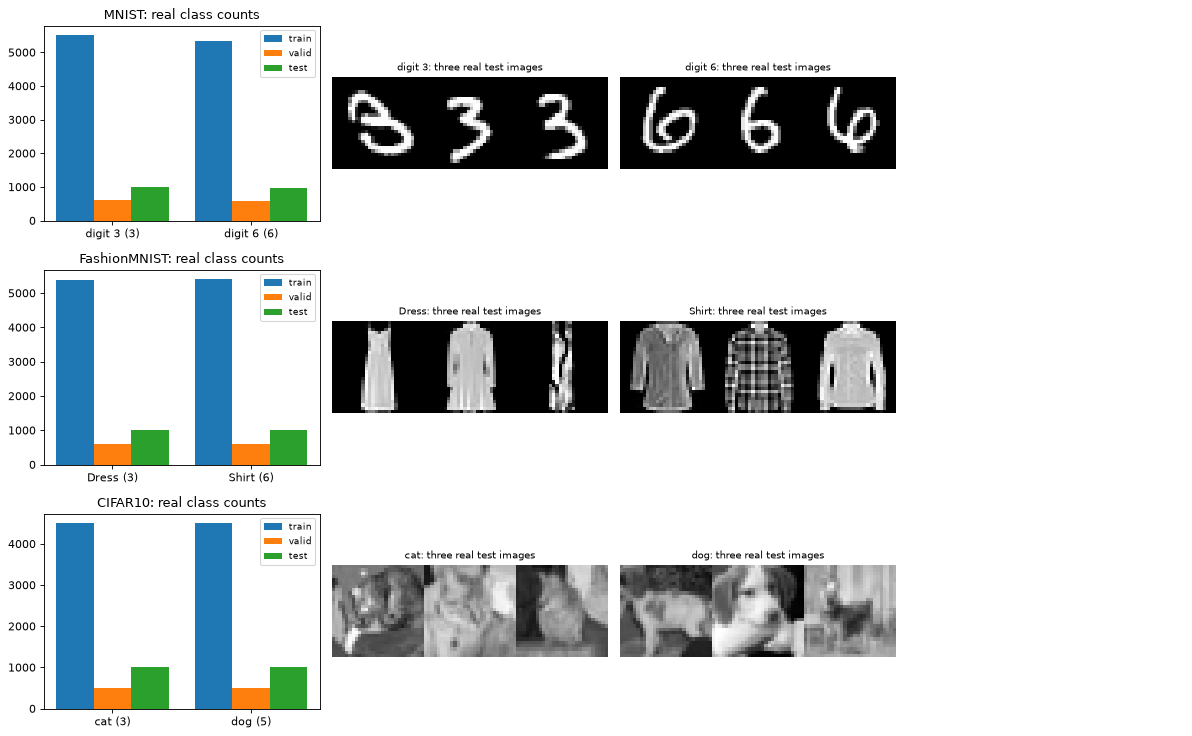

In [7]:
# ---- 2.2 bar charts of the real classes and real example images (the paper's Fig. 1) ----
fig, ax = plt.subplots(len(DATASETS), 4, figsize=(15, 3.1 * len(DATASETS)), squeeze=False)
for r, name in enumerate(DATASETS):
    d, info = DATA[name], INFO[name]
    cnt = np.array([[int((d[s][3] == v).sum()) for v in info["digits"]] for s in ("train", "valid", "test")])
    xs = np.arange(len(info["digits"]))
    for i, s in enumerate(("train", "valid", "test")):
        ax[r, 0].bar(xs + (i - 1) * 0.27, cnt[i], 0.27, label=s)
    ax[r, 0].set_xticks(xs); ax[r, 0].set_xticklabels([f"{CLASS_NAMES[name][v]} ({v})" for v in info["digits"]]); ax[r, 0].set_title(f"{name}: real class counts"); ax[r, 0].legend(fontsize=8)
    pix = d["test"][2]; lab = d["test"][3]
    for j, v in enumerate(info["digits"]):
        idx = np.flatnonzero(lab == v)[:3]
        strip = np.concatenate([pix[i] for i in idx], axis=1)
        ax[r, 1 + j].imshow(strip, cmap="gray", vmin=0, vmax=1); ax[r, 1 + j].axis("off"); ax[r, 1 + j].set_title(f"{CLASS_NAMES[name][v]}: three real test images", fontsize=9)
    ax[r, 3].axis("off")
plt.tight_layout(); plt.show()

MNIST explained variance of the 2 PCA coordinates (pooled inputs): [0.267 0.212]


FashionMNIST explained variance of the 2 PCA coordinates (pooled inputs): [0.616 0.214]


CIFAR10 explained variance of the 2 PCA coordinates (pooled inputs): [0.374 0.188]


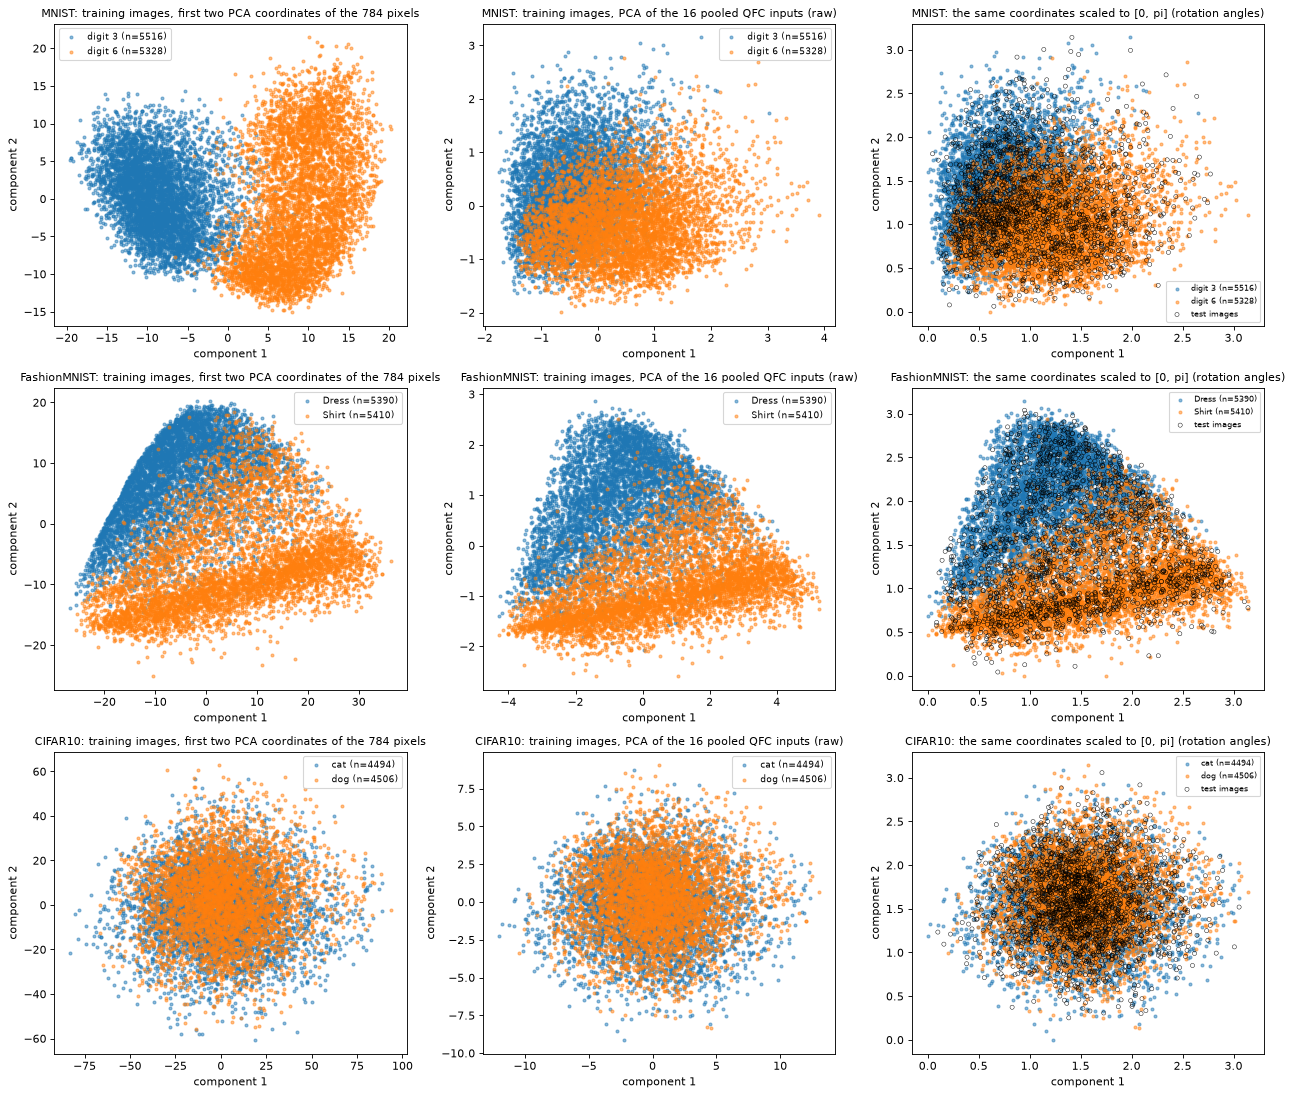

In [8]:
# ---- 2.3 two-dimensional scatter of real observations coloured by ground-truth label (PCA fitted on the training split) ----
POOL = lambda X: F.avg_pool2d(X, 6).reshape(len(X), 16).numpy()          # the 16 values the QFC encodes as rotation angles
fig, ax = plt.subplots(len(DATASETS), 3, figsize=(16, 4.6 * len(DATASETS)), squeeze=False)
for r, name in enumerate(DATASETS):
    d, info = DATA[name], INFO[name]
    Xtr, ytr = d["train"][0], d["train"][1].numpy(); Xte, yte = d["test"][0], d["test"][1].numpy()
    cols = ["tab:blue", "tab:orange"]; labn = [CLASS_NAMES[name][v] for v in info["digits"]]
    def scat(a, P, y, title):
        for k in (0, 1):
            m = y == k
            a.scatter(P[m, 0], P[m, 1], s=7, alpha=0.5, c=cols[k], label=f"{labn[k]} (n={m.sum()})")
        a.set_title(title, fontsize=10); a.legend(fontsize=8); a.set_xlabel("component 1"); a.set_ylabel("component 2")
    pca_px = PCA(2, random_state=SEED).fit(Xtr.reshape(len(Xtr), -1).numpy())
    scat(ax[r, 0], pca_px.transform(Xtr.reshape(len(Xtr), -1).numpy()), ytr, f"{name}: training images, first two PCA coordinates of the 784 pixels")
    Ptr, Pte = POOL(Xtr), POOL(Xte)
    pca_q = PCA(2, random_state=SEED).fit(Ptr)
    Ztr, Zte = pca_q.transform(Ptr), pca_q.transform(Pte)
    scat(ax[r, 1], Ztr, ytr, f"{name}: training images, PCA of the 16 pooled QFC inputs (raw)")
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)
    scat(ax[r, 2], mm.transform(Ztr), ytr, f"{name}: the same coordinates scaled to [0, pi] (rotation angles)")
    ax[r, 2].scatter(*np.clip(mm.transform(Zte), 0, np.pi).T, s=14, facecolors="none", edgecolors="k", linewidths=0.4, label="test images")
    ax[r, 2].legend(fontsize=7)
    print(name, "explained variance of the 2 PCA coordinates (pooled inputs):", np.round(pca_q.explained_variance_ratio_, 3))
plt.tight_layout(); plt.show()

## 3. The two models

### 3.1 QFC: the quantum fully connected network

The QFC is the TorchQuantum example model. For an image `x` (28 x 28, standardised):

1. **Pooling.** `avg_pool2d(x, 6)` gives a 4 x 4 image, i.e. 16 numbers `f_0 ... f_15`.
2. **Encoder `4x4_u3_h_rx`** (4 qubits, all start in |0>): qubit 0 gets `U3(f_0, f_1, f_2)`, `RX(f_3)` and then `H`; qubits 1, 2, 3 get `H`, `U3(f_4k, f_4k+1, f_4k+2)`
   and `RX(f_4k+3)`. The pooled pixel values are used **directly as angles in radians**.
3. **Processing layer.** 50 random gates (each RX, RY, RZ with a trainable angle, or a CNOT; random wires), then trainable `RX(q0)`, `RY(q1)`, `RZ(q3)`, `CRX(q0 -> q2)`, then the
   fixed gates `H(q3)`, `SX(q2)`, `CNOT(q3 -> q0)` and `RX(0.1)` on q1.
4. **Read-out.** The expectation of Pauli-Z on each qubit; the two logits are `<Z0> + <Z1>` and `<Z2> + <Z3>`; log-softmax.

Because the encoder acts on |0000> and only has single-qubit gates, the encoded state is a product state that we compute in closed form; the processing layer does not depend on the
input, so its 16 x 16 unitary is built once per forward pass by multiplying the 58 gate matrices. Gradients with respect to **both** the circuit angles (training) and the
input pixels (the attacks) flow through this simulation by back-propagation, exactly as TorchQuantum does. The circuit section that follows proves, with a Qiskit circuit,
that this simulator implements the circuit it claims to.

### 3.2 CFC: the classical counterpart

`Conv2d(1, 4, kernel 6, stride 6)`, flatten (64 values), `Linear(64, 32)`-ReLU-dropout(0.3), `Linear(32, 16)`-ReLU-dropout(0.3), `Linear(16, 4)`-ReLU, `Linear(4, 10)` and log-softmax
(10 outputs although only two classes exist: that is what the released code does).

In [9]:
# ---- 3.1 the two models of the paper: QFC (exact 4-qubit simulator) and CFC (classical network) ----
import math, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F

N_WIRES = 4
CDT = torch.complex128

# ---------------------------------------------------------------- gate list (single source of truth)
def make_gate_list(seed, n_random_ops=50):
    """Random layer (RX/RY/RZ/CNOT, 50 ops) followed by the fixed TorchQuantum QLayer tail.
    Each entry: (name, wires, param_index or None, fixed_angle or None)."""
    rng = np.random.default_rng(seed)
    gl, p = [], 0
    for _ in range(n_random_ops):
        name = str(rng.choice(["rx", "ry", "rz", "cnot"]))
        if name == "cnot":
            w = tuple(int(v) for v in rng.choice(N_WIRES, size=2, replace=False)); gl.append(("cnot", w, None, None))
        else:
            w = (int(rng.choice(N_WIRES)),); gl.append((name, w, p, None)); p += 1
    gl += [("rx", (0,), p, None), ("ry", (1,), p + 1, None), ("rz", (3,), p + 2, None), ("crx", (0, 2), p + 3, None),
           ("h", (3,), None, None), ("sx", (2,), None, None), ("cnot", (3, 0), None, None), ("rx", (1,), None, 0.1)]
    return gl, p + 4

def rx_m(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
def ry_m(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c + 0j, -s + 0j], -1), torch.stack([s + 0j, c + 0j], -1)], -2)
def rz_m(t):
    e = torch.exp(-0.5j * t)
    z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
H_M = torch.tensor([[1, 1], [1, -1]], dtype=CDT) / math.sqrt(2)
SX_M = torch.tensor([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]], dtype=CDT) / 2

def crx_m(t):
    P0 = torch.tensor([[1, 0], [0, 0]], dtype=CDT); P1 = torch.tensor([[0, 0], [0, 1]], dtype=CDT)
    I2 = torch.eye(2, dtype=CDT)
    return (torch.kron(P0, I2) + torch.kron(P1, rx_m(t))).reshape(2, 2, 2, 2)

ZSIGN = torch.tensor([[1 - 2 * ((i >> (3 - w)) & 1) for w in range(4)] for i in range(16)], dtype=torch.float64)  # [16,4], wire 0 = MSB

def _embed_consts():
    """E[w][a,b] = 16x16 matrix that applies |a><b| on wire w (wire 0 = most significant bit) and identity elsewhere."""
    E = torch.zeros(4, 2, 2, 16, 16, dtype=CDT)
    for w in range(4):
        sh = 3 - w
        for i in range(16):
            for j in range(16):
                if (i & ~(1 << sh)) == (j & ~(1 << sh)):
                    E[w, (i >> sh) & 1, (j >> sh) & 1, i, j] = 1
    return E
E_ALL = _embed_consts()
def _cnot16(c, t):
    M = torch.zeros(16, 16, dtype=CDT)
    for j in range(16):
        i = j ^ (1 << (3 - t)) if (j >> (3 - c)) & 1 else j
        M[i, j] = 1
    return M

class QFC(nn.Module):
    """TorchQuantum QFCModel re-implemented as an exact 4-qubit state-vector simulator in PyTorch."""
    def __init__(self, seed=0, n_random_ops=50):
        super().__init__()
        self.gate_list, self.n_params = make_gate_list(seed, n_random_ops)
        g = torch.Generator().manual_seed(seed)
        self.theta = nn.Parameter((torch.rand(self.n_params, generator=g, dtype=torch.float64) * 2 - 1) * math.pi)
        self.seed = seed
        self._Ufix = None
        n = len(self.gate_list)
        self._n = n
        # constant parts of every gate as a 16x16 matrix (CNOT, CRX control-0 block) and the embedding tensors
        const = torch.zeros(n, 16, 16, dtype=CDT)
        emb = torch.zeros(n, 2, 2, 16, 16, dtype=CDT)
        for k, (name, w, pi_, fixed) in enumerate(self.gate_list):
            if name == "cnot": const[k] = _cnot16(*w)
            elif name == "crx":
                c, t = w
                P0 = E_ALL[c, 0, 0]; P1 = E_ALL[c, 1, 1]
                const[k] = P0
                emb[k] = torch.einsum("ij,abjk->abik", P1, E_ALL[t])
            else: emb[k] = E_ALL[w[0]]
        self.register_buffer("const", const); self.register_buffer("emb", emb)
        kinds = {"rx": 0, "ry": 1, "rz": 2, "h": 3, "sx": 4, "cnot": 5, "crx": 0}
        self._kind = [kinds[g_[0]] for g_ in self.gate_list]
        self._pidx = [g_[2] if g_[2] is not None else -1 for g_ in self.gate_list]
        self._fixed = [g_[3] for g_ in self.gate_list]

    def gate_mats(self):
        """[n,2,2] single-qubit (or CRX target) matrices of every gate, built with 3 vectorised calls."""
        ang = torch.stack([self.theta[p] if p >= 0 else torch.tensor(f if f is not None else 0.0, dtype=torch.float64)
                           for p, f in zip(self._pidx, self._fixed)])
        kind = torch.tensor(self._kind)
        rx, ry, rz = rx_m(ang), ry_m(ang), rz_m(ang)
        G = torch.zeros(self._n, 2, 2, dtype=CDT)
        sel = lambda k: (kind == k).view(-1, 1, 1)
        G = torch.where(sel(0), rx, G); G = torch.where(sel(1), ry, G); G = torch.where(sel(2), rz, G)
        G = torch.where(sel(3), H_M.expand(self._n, 2, 2), G); G = torch.where(sel(4), SX_M.expand(self._n, 2, 2), G)
        return G

    def unitary(self):
        mats = self.const + torch.einsum("nab,nabij->nij", self.gate_mats(), self.emb)
        size = 1
        while size < self._n: size *= 2
        if size > self._n:
            mats = torch.cat([mats, torch.eye(16, dtype=CDT).expand(size - self._n, 16, 16)], 0)
        while mats.shape[0] > 1:
            mats = mats[1::2] @ mats[0::2]
        return mats[0]

    def freeze(self):
        with torch.no_grad(): self._Ufix = self.unitary()
    def unfreeze(self):
        self._Ufix = None
    @staticmethod
    def pool(x):
        return F.avg_pool2d(x, 6).reshape(x.shape[0], 16)
    @staticmethod
    def encode(f):
        """f: [B,16] pooled pixels -> [B,16] complex product state of the TorchQuantum '4x4_u3_h_rx' encoder
        (wire 0: U3, RX, H; wires 1-3: H, U3, RX), evaluated in closed form per qubit."""
        f = f.to(torch.float64)
        B = f.shape[0]
        r2 = math.sqrt(0.5)
        vs = []
        for k in range(4):
            th, ph, la, al = f[:, 4 * k], f[:, 4 * k + 1], f[:, 4 * k + 2], f[:, 4 * k + 3]
            c1, s1 = torch.cos(th / 2), torch.sin(th / 2)
            eph = torch.polar(torch.ones_like(ph), ph); ela = torch.polar(torch.ones_like(la), la)
            if k == 0:
                v0, v1 = c1 + 0j, eph * s1
            else:
                v0, v1 = (c1 - ela * s1) * r2, (eph * s1 + eph * ela * c1) * r2
            c, s = torch.cos(al / 2), torch.sin(al / 2)
            w0, w1 = c * v0 - 1j * s * v1, -1j * s * v0 + c * v1
            if k == 0:
                w0, w1 = (w0 + w1) * r2, (w0 - w1) * r2
            vs.append(torch.stack([w0, w1], 1))
        return (vs[0][:, :, None, None, None] * vs[1][:, None, :, None, None] * vs[2][:, None, None, :, None] * vs[3][:, None, None, None, :]).reshape(B, 16)
    def expz(self, x):
        U = self._Ufix if self._Ufix is not None else self.unitary()
        psi = self.encode(self.pool(x)) @ U.T
        p = psi.real ** 2 + psi.imag ** 2
        return p @ ZSIGN

    def forward(self, x):
        z = self.expz(x)
        logits = torch.stack([z[:, 0] + z[:, 1], z[:, 2] + z[:, 3]], 1)
        return F.log_softmax(logits, 1).to(torch.float32)

class CFC(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 4, kernel_size=6, stride=6)
        self.fc1, self.fc2, self.fc3 = nn.Linear(64, 32), nn.Linear(32, 16), nn.Linear(16, 4)
        self.drop = nn.Dropout(0.3)
        self.out = nn.Linear(4, 10)
    def forward(self, x):
        x = torch.flatten(self.conv(x), 1)
        x = self.drop(F.relu(self.fc1(x))); x = self.drop(F.relu(self.fc2(x))); x = F.relu(self.fc3(x))
        return F.log_softmax(self.out(x), 1)

## Quantum Circuit Architecture

The only quantum model of the paper is the QFC (the CFC is classical). This section draws **the circuit that the simulator executes**, built from the very same gate list
(`model.gate_list`) and with symbolic input angles `x[0..15]` (the pooled pixels) and symbolic trainable angles `w[...]`. It then binds numbers to it, runs it with Qiskit's
`Statevector`, and **asserts that the PyTorch simulator gives the same state (fidelity 1) and the same Pauli-Z expectation values**. The drawing shows the encoding block, the 50-gate
random layer, the trainable and fixed gates, the CNOT entanglers and the Pauli-Z measurements.

Assumptions where the paper is silent: the random layer is one random draw (RX / RY / RZ / CNOT with equal probability, 1 or 2 random wires) that depends on the seed - TorchQuantum's own draw cannot be reproduced
because it uses an unseeded NumPy state; the paper says only "random quantum layers and parametrized gates (RX, RY, RZ, CRX)". The gate order and the encoder are taken from the TorchQuantum source.
The read-out is the exact expectation value (no shots), as in TorchQuantum's `MeasureAll(PauliZ)`.

In [10]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

def qfc_qiskit_circuit(model, symbolic=True, f=None, theta=None):
    # The executed circuit: encoder (angles f) + the gate list of the model (angles theta). Qubit k = TorchQuantum wire k.
    x = ParameterVector("x", 16) if symbolic else f
    w = ParameterVector("w", model.n_params) if symbolic else theta
    qc = QuantumCircuit(N_QUBITS)
    for k in range(4):
        a = x[4 * k:4 * k + 4]
        if k == 0: qc.u(a[0], a[1], a[2], 0); qc.rx(a[3], 0); qc.h(0)
        else:      qc.h(k); qc.u(a[0], a[1], a[2], k); qc.rx(a[3], k)
    qc.barrier()
    for name, wires, pi_, fixed in model.gate_list:
        ang = w[pi_] if pi_ is not None else fixed
        if   name == "rx":   qc.rx(ang, wires[0])
        elif name == "ry":   qc.ry(ang, wires[0])
        elif name == "rz":   qc.rz(ang, wires[0])
        elif name == "h":    qc.h(wires[0])
        elif name == "sx":   qc.sx(wires[0])
        elif name == "cnot": qc.cx(wires[0], wires[1])
        elif name == "crx":  qc.crx(ang, wires[0], wires[1])
    return qc

def assert_equivalent(model, X, n=6, tol=1e-9):
    # Assert: PyTorch simulator == Qiskit statevector (fidelity) and == Qiskit Pauli-Z expectations, for n real images.
    with torch.no_grad():
        f = QFC.pool(X[:n]); psi = QFC.encode(f) @ model.unitary().T; ez = model.expz(X[:n]).numpy()
    th = model.theta.detach().numpy()
    worst_f, worst_z = 1.0, 0.0
    for b in range(n):
        qc = qfc_qiskit_circuit(model, False, f[b].double().numpy(), th)
        sv = Statevector(qc)
        s = np.transpose(sv.data.reshape(2, 2, 2, 2), (3, 2, 1, 0)).reshape(16)       # Qiskit is little-endian, TorchQuantum wire 0 is the most significant bit
        worst_f = min(worst_f, abs(np.vdot(s, psi[b].numpy())) ** 2)
        zq = [sv.expectation_value(SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], N_QUBITS)).real for k in range(4)]
        worst_z = max(worst_z, float(np.max(np.abs(np.array(zq) - ez[b]))))
    assert worst_f > 1 - tol and worst_z < 1e-7, (worst_f, worst_z)
    return worst_f, worst_z

demo_model = QFC(seed=SEED)
qc_sym = qfc_qiskit_circuit(demo_model)
print(f"qubits = {qc_sym.num_qubits} | circuit depth = {qc_sym.depth()} | gates = {qc_sym.size()} | "
      f"trainable parameters = {demo_model.n_params} (QFC) | input angles = {len(qc_sym.parameters) - demo_model.n_params}")
print("gate counts:", dict(qc_sym.count_ops()))
fid, dz = assert_equivalent(demo_model, DATA[MAIN]["test"][0])
print(f"EQUIVALENCE ASSERTED: PyTorch simulator vs Qiskit Statevector on 6 real MNIST test images: worst fidelity {fid:.12f}, worst |<Z> difference| {dz:.2e}")

qubits = 4 | circuit depth = 29 | gates = 70 | trainable parameters = 42 (QFC) | input angles = 16
gate counts: {'rz': 18, 'rx': 17, 'cx': 13, 'ry': 11, 'h': 5, 'u': 4, 'barrier': 1, 'crx': 1, 'sx': 1}
EQUIVALENCE ASSERTED: PyTorch simulator vs Qiskit Statevector on 6 real MNIST test images: worst fidelity 1.000000000000, worst |<Z> difference| 1.05e-15


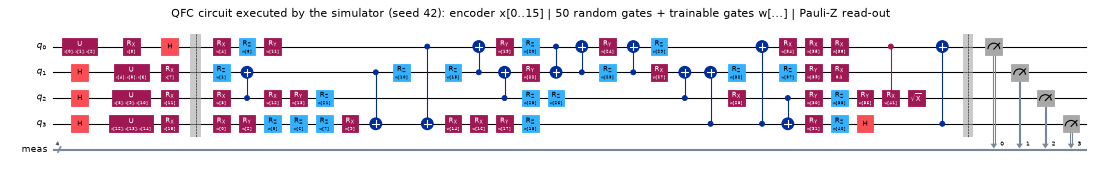

In [11]:
# the drawing of the executed circuit (measurements added only for the picture: the model reads exact <Z>, i.e. infinitely many shots)
qc_draw = qc_sym.copy(); qc_draw.measure_all()
fig = qc_draw.draw("mpl", fold=60, scale=0.5, style={"name": "iqp"})
fig.suptitle("QFC circuit executed by the simulator (seed %d): encoder x[0..15] | 50 random gates + trainable gates w[...] | Pauli-Z read-out" % SEED, fontsize=10)
display(fig)                      # Qiskit closes its own figure, so show it explicitly

## 4. Training the models and the classical baselines

Both models are trained as in the released code: Adam, learning rate 5e-3, weight decay 1e-4, a cosine schedule over the epochs, batch size 256, negative log-likelihood loss. Each **seed** gives a different
random circuit and parameter initialisation for the QFC, a different initialisation for the CFC, and a different batch order. Two classical scikit-learn baselines (Random Forest, RBF-SVM) are trained on the
**same 16 pooled inputs as the QFC** (training split only); they cannot be attacked with gradients, so they serve as extra targets of transferred attacks in Section 6.

With `RUN_AT = True` the notebook also trains the **adversarially trained** versions (Section 7); that happens in Section 5.3, once the attacks exist.

In [12]:
# ---- 4.1 training, prediction and accuracy helpers ----
@torch.no_grad()
def predict(model, X, bs=1024):
    was = model.training; model.eval()
    if hasattr(model, "freeze"): model.freeze()
    p = torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])
    if hasattr(model, "unfreeze"): model.unfreeze()
    model.train(was)
    return p

def accuracy(model, X, y):
    return (predict(model, X) == y).float().mean().item()

def train_model(model, data, epochs, seed, lr=5e-3, wd=1e-4, bs=256, adv=None, log=None):
    """Adam + cosine schedule as in the ATTAQ repository. adv = dict(attacks=[...], lo=, hi=) switches on adaptive online adversarial training."""
    Xtr, ytr = data["train"][0], data["train"][1]
    Xva, yva = data["valid"][0], data["valid"][1]
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    gen = torch.Generator().manual_seed(seed)
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]; xb, yb = Xtr[idx], ytr[idx]
            loss = F.nll_loss(model(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
            if adv is not None:
                eps_ep = ep / epochs
                for atk in adv["attacks"]:
                    xa = ATTACKS[atk](model, xb, yb, eps_ep, adv["lo"], adv["hi"])
                    la = F.nll_loss(model(xa), yb); opt.zero_grad(); la.backward(); opt.step()
        sched.step()
        va = accuracy(model, Xva, yva); hist.append(va)
        if log: log(ep, loss.item(), va)
    return hist

In [13]:
# ---- 4.2 train QFC and CFC (clean) for every seed, the sklearn baselines, and the adversarially trained copies ----
def make_models(seed):
    torch.manual_seed(seed)
    return dict(QFC=QFC(seed=seed), CFC=CFC())

MODELS, CLF, TRAIN_TIME, HIST, AT_MODELS = {}, {}, {}, {}, {}
for name in DATASETS:
    d, info = DATA[name], INFO[name]
    n_seeds = N_SEEDS if name == MAIN else 1               # the two extra datasets use one seed
    for s in range(n_seeds):
        seed = SEED + s
        ms = make_models(seed)
        for mname, m in ms.items():
            t0 = time.time()
            HIST[(name, seed, mname)] = train_model(m, d, EPOCHS, seed, bs=BS)
            TRAIN_TIME[(name, seed, mname)] = time.time() - t0
            print(f"{name:13s} seed {seed} {mname}: validation accuracy per epoch {np.round(HIST[(name, seed, mname)], 3).tolist()}  ({TRAIN_TIME[(name, seed, mname)]:.0f} s)")
        MODELS[(name, seed)] = ms
    Ptr = POOL(d["train"][0]); ytr = d["train"][1].numpy()
    CLF[name] = dict(RF=RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Ptr, ytr),
                     SVC=SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(Ptr, ytr))      # CHOICE: default hyper-parameters
print("clean training finished after %.0f s" % (time.time() - T_START))

MNIST         seed 42 QFC: validation accuracy per epoch [0.749, 0.861, 0.866, 0.871, 0.871, 0.866, 0.869, 0.869, 0.867, 0.867]  (24 s)


MNIST         seed 42 CFC: validation accuracy per epoch [0.991, 0.993, 0.995, 0.996, 0.998, 0.998, 0.998, 0.998, 0.998, 0.998]  (11 s)


MNIST         seed 43 QFC: validation accuracy per epoch [0.818, 0.842, 0.848, 0.843, 0.851, 0.855, 0.851, 0.855, 0.856, 0.856]  (14 s)


MNIST         seed 43 CFC: validation accuracy per epoch [0.992, 0.994, 0.993, 0.995, 0.994, 0.998, 0.997, 0.998, 0.998, 0.998]  (8 s)


MNIST         seed 44 QFC: validation accuracy per epoch [0.666, 0.759, 0.795, 0.827, 0.846, 0.855, 0.861, 0.862, 0.863, 0.863]  (9 s)


...

FashionMNIST  seed 42 QFC: validation accuracy per epoch [0.738, 0.74, 0.747, 0.739, 0.734, 0.733, 0.738, 0.738, 0.736, 0.738]  (14 s)


FashionMNIST  seed 42 CFC: validation accuracy per epoch [0.879, 0.908, 0.916, 0.916, 0.924, 0.925, 0.927, 0.925, 0.929, 0.928]  (8 s)


CIFAR10       seed 42 QFC: validation accuracy per epoch [0.49, 0.507, 0.497, 0.489, 0.487, 0.485, 0.486, 0.49, 0.49, 0.49]  (14 s)


CIFAR10       seed 42 CFC: validation accuracy per epoch [0.537, 0.518, 0.529, 0.584, 0.583, 0.535, 0.589, 0.586, 0.587, 0.588]  (6 s)


clean training finished after 204 s


acc_mean  acc_std  f1_mean  n
dataset      model                                                
MNIST        QFC                       0.8845   0.0051   0.8845  3
             CFC                       0.9968   0.0008   0.9968  3
             RF (16 pooled inputs)     0.9934      NaN   0.9934  1
             SVC (16 pooled inputs)    0.9934      NaN   0.9934  1
FashionMNIST QFC                       0.7230      NaN   0.7229  1
             CFC                       0.9285      NaN   0.9285  1
             RF (16 pooled inputs)     0.9255      NaN   0.9255  1
             SVC (16 pooled inputs)    0.9110      NaN   0.9110  1
CIFAR10      QFC                       0.5070      NaN   0.5052  1
             CFC                       0.5915      NaN   0.5906  1
             RF (16 pooled inputs)     0.6310      NaN   0.6304  1
             SVC (16 pooled inputs)    0.6320      NaN   0.6314  1

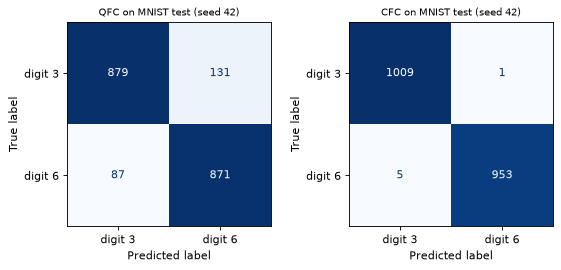

MNIST seed 42: trained QFC == Qiskit circuit with the trained angles (fidelity 1.000000000000, max |dZ| 8.6e-16)
MNIST seed 43: trained QFC == Qiskit circuit with the trained angles (fidelity 1.000000000000, max |dZ| 1.4e-15)
MNIST seed 44: trained QFC == Qiskit circuit with the trained angles (fidelity 1.000000000000, max |dZ| 1.0e-15)


FashionMNIST seed 42: trained QFC == Qiskit circuit with the trained angles (fidelity 1.000000000000, max |dZ| 1.1e-15)
CIFAR10 seed 42: trained QFC == Qiskit circuit with the trained angles (fidelity 1.000000000000, max |dZ| 7.5e-16)


In [14]:
# ---- 4.4 clean results: accuracy, F1, confusion matrices (attack class = model label 1 as the positive class) ----
def clean_row(dataset, seed, mname, model):
    d = DATA[dataset]; Xte, yte = d["test"][0], d["test"][1]
    p = predict(model, Xte)
    return dict(dataset=dataset, seed=seed, model=mname, acc=(p == yte).float().mean().item(), f1=f1_score(yte, p, average="weighted"))
rows = []
for (name, seed), ms in MODELS.items():
    for mname, m in ms.items(): rows.append(clean_row(name, seed, mname, m))
    for cname, clf in (CLF[name].items() if seed == SEED else []):          # RF / SVC are deterministic: one row per dataset
        p = clf.predict(POOL(DATA[name]["test"][0])); yte = DATA[name]["test"][1].numpy()
        rows.append(dict(dataset=name, seed=seed, model=cname + " (16 pooled inputs)", acc=float((p == yte).mean()), f1=f1_score(yte, p, average="weighted")))
for (name, seed), ms in AT_MODELS.items():
    for mname, m in ms.items(): rows.append(clean_row(name, seed, mname + "_AT", m))
CLEAN = pd.DataFrame(rows)
summary = CLEAN.groupby(["dataset", "model"], sort=False).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"), n=("seed", "count")).round(4)
display(summary)

name = MAIN; seed0 = SEED; d = DATA[name]; Xte, yte = d["test"][0], d["test"][1]
panels = [("QFC", MODELS[(name, seed0)]["QFC"]), ("CFC", MODELS[(name, seed0)]["CFC"])] + [(k + "_AT", m) for k, m in AT_MODELS.get((name, seed0), {}).items()]
fig, ax = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.4))
for a, (k, m) in zip(np.atleast_1d(ax), panels):
    ConfusionMatrixDisplay(confusion_matrix(yte, predict(m, Xte), labels=[0, 1]), display_labels=[CLASS_NAMES[name][v] for v in INFO[name]["digits"]]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{k} on {name} test (seed {seed0})", fontsize=9)
plt.tight_layout(); plt.show()

# the executed circuit == the trained model: assert again with the trained angles
for (nm, sd), ms in MODELS.items():
    f_, z_ = assert_equivalent(ms["QFC"], DATA[nm]["test"][0], n=4)
    print(f"{nm} seed {sd}: trained QFC == Qiskit circuit with the trained angles (fidelity {f_:.12f}, max |dZ| {z_:.1e})")

## 5. The attacks

Five evasion attacks, all L-infinity and white-box (they use the gradient of the **source** model with respect to the input pixels), written with the defaults of `torchattacks 3.5.1`:

| Attack | Idea | Default settings used by the authors |
|---|---|---|
| FGSM | one step `x + eps * sign(grad)` | eps |
| BIM | 10 small steps of size alpha, kept in the eps-box | alpha = 2/255, 10 steps |
| PGD | BIM with a random start inside the eps-box | alpha = 2/255, 10 steps |
| RFGSM | random sign step of size alpha, then 10 gradient steps | alpha = 2/255, 10 steps |
| APGD | Auto-PGD: adaptive step size, momentum, restarts from the best point | 10 steps, 1 restart, cross-entropy |

Two consequences of those defaults matter for reading the results. **(i)** BIM, PGD and RFGSM move each pixel by at most 10 x 2/255 = 0.078 whatever eps is, so their ASR saturates; FGSM
and APGD use the full budget. **(ii)** The inputs are standardised (range about [-0.42, 2.82]) but `torchattacks` clamps every adversarial image to [0, 1]. In **"released" mode** we copy this: the black
background (-0.42) is lifted to 0 and bright strokes (up to 2.82) are cut to 1 *even for a tiny eps*. In **"valid range" mode** we clamp to [-0.42, 2.82] instead (eps then equals eps x 0.31 in
pixel units, i.e. eps = 1.0 is the usual MNIST budget 0.31). Both are reported; the paper's numbers are compared with the released mode first.

The loss is the cross-entropy on the model's output; because the models output log-probabilities this is the same as the negative log-likelihood. The attacks put the model in evaluation mode (no dropout) and restore it afterwards.

In [15]:
# ---- 5.1 the attacks (torchattacks 3.5.1 defaults, our own code) ----
from contextlib import contextmanager

@contextmanager
def attack_mode(model):
    was_training = model.training
    model.eval()
    if hasattr(model, "freeze"): model.freeze()
    try:
        yield
    finally:
        if hasattr(model, "unfreeze"): model.unfreeze()
        model.train(was_training)

def input_grad(model, x, y):
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)          # model outputs log-probabilities; CE(log_softmax) == NLL
    return torch.autograd.grad(loss, x)[0]

def fgsm(model, x, y, eps, lo, hi):
    with attack_mode(model):
        return torch.clamp(x + eps * input_grad(model, x, y).sign(), lo, hi).detach()

def bim(model, x, y, eps, lo, hi, alpha=2 / 255, steps=10):
    with attack_mode(model):
        ori, cur = x.clone(), x.clone()
        for _ in range(steps):
            adv = cur + alpha * input_grad(model, cur, y).sign()
            a = torch.clamp(ori - eps, min=lo)
            b = torch.where(adv >= a, adv, a)
            c = torch.where(b > ori + eps, ori + eps, b)
            cur = torch.clamp(c, max=hi).detach()
        return cur

def pgd(model, x, y, eps, lo, hi, alpha=2 / 255, steps=10, random_start=True):
    with attack_mode(model):
        adv = x.clone()
        if random_start:
            adv = torch.clamp(adv + torch.empty_like(adv).uniform_(-eps, eps), lo, hi)
        for _ in range(steps):
            adv = adv + alpha * input_grad(model, adv, y).sign()
            adv = torch.clamp(x + torch.clamp(adv - x, -eps, eps), lo, hi).detach()
        return adv

def rfgsm(model, x, y, eps, lo, hi, alpha=2 / 255, steps=10):
    with attack_mode(model):
        adv = torch.clamp(x + alpha * torch.randn_like(x).sign(), lo, hi)
        for _ in range(steps):
            adv = adv + alpha * input_grad(model, adv, y).sign()
            adv = torch.clamp(x + torch.clamp(adv - x, -eps, eps), lo, hi).detach()
        return adv

def apgd(model, x, y, eps, lo, hi, steps=10, rho=0.75, seed=0):
    """Auto-PGD (Croce & Hein 2020), L-inf, cross-entropy loss, one restart; only initially-correct samples are attacked."""
    with attack_mode(model):
        out = x.clone()
        with torch.no_grad():
            correct = model(x).argmax(1) == y
        idx = correct.nonzero().squeeze(1)
        if idx.numel() == 0: return out
        xs, ys = x[idx], y[idx]
        n = xs.shape[0]
        gen = torch.Generator().manual_seed(seed)
        steps_2, steps_min, size_decr = max(int(0.22 * steps), 1), max(int(0.06 * steps), 1), max(int(0.03 * steps), 1)
        def gl(xa):
            xa = xa.clone().detach().requires_grad_(True)
            lg = model(xa); li = F.cross_entropy(lg, ys, reduction="none")
            return torch.autograd.grad(li.sum(), xa)[0], lg.detach(), li.detach()
        t = 2 * torch.rand(xs.shape, generator=gen) - 1
        x_adv = torch.clamp(xs + eps * t / t.reshape(n, -1).abs().max(1)[0].view(-1, 1, 1, 1), lo, hi)
        x_best, x_best_adv = x_adv.clone(), x_adv.clone()
        loss_steps = torch.zeros(steps, n)
        grad, lg, li = gl(x_adv)
        acc = lg.argmax(1) == ys
        loss_best = li.clone(); grad_best = grad.clone()
        step = torch.full((n, 1, 1, 1), 2.0 * eps)
        x_old = x_adv.clone(); counter3 = 0; k = steps_2
        loss_best_last = loss_best.clone(); reduced_last = torch.ones(n, dtype=torch.bool)
        for i in range(steps):
            with torch.no_grad():
                grad2 = x_adv - x_old; x_old = x_adv.clone()
                a = 0.75 if i > 0 else 1.0
                x1 = torch.clamp(torch.min(torch.max(x_adv + step * grad.sign(), xs - eps), xs + eps), lo, hi)
                x1 = torch.clamp(torch.min(torch.max(x_adv + (x1 - x_adv) * a + grad2 * (1 - a), xs - eps), xs + eps), lo, hi)
                x_adv = x1
            grad, lg, li = gl(x_adv)
            pred = lg.argmax(1) == ys
            acc = acc & pred
            x_best_adv[~pred] = x_adv[~pred]
            loss_steps[i] = li
            better = li > loss_best
            x_best[better] = x_adv[better]; grad_best[better] = grad[better]; loss_best[better] = li[better]
            counter3 += 1
            if counter3 == k:
                tcount = torch.zeros(n)
                for c5 in range(k): tcount += (loss_steps[i - c5] > loss_steps[i - c5 - 1]).float()
                osc = tcount <= k * rho
                no_impr = (~reduced_last) & (loss_best_last >= loss_best)
                osc = osc | no_impr
                reduced_last = osc.clone(); loss_best_last = loss_best.clone()
                if osc.any():
                    step[osc] = step[osc] / 2.0
                    x_adv[osc] = x_best[osc]; grad[osc] = grad_best[osc]
                counter3 = 0; k = max(k - size_decr, steps_min)
        fooled = ~acc
        out[idx[fooled]] = x_best_adv[fooled]
        return out.detach()

ATTACKS = {"APGD": apgd, "BIM": bim, "FGSM": fgsm, "PGD": pgd, "RFGSM": rfgsm}

def run_attack(name, model, X, y, eps, lo, hi, bs=512):
    return torch.cat([ATTACKS[name](model, X[i:i + bs], y[i:i + bs], eps, lo, hi) for i in range(0, len(X), bs)])

### 5.1 Check against `torchattacks`

To be sure our code is the same attack as the one the authors ran, the next cell runs both implementations on the same trained models, the same images and (for the random attacks) the same random seed, and compares
the adversarial images. FGSM and BIM are deterministic and must agree exactly. If `torchattacks` cannot be imported (it is not needed for anything else) the cell says so and is skipped.

In [16]:
# ---- 5.1 numerical cross-check against torchattacks 3.5.1 (skipped if the package is unavailable) ----
tamod = None
if CROSSCHECK_TORCHATTACKS:
    if importlib.util.find_spec("torchattacks") is None and IN_COLAB:
        %pip install -q "torchattacks==3.5.1"
    try:
        import torchattacks as tamod
        print("torchattacks", getattr(tamod, "__version__", "?"))
    except Exception as e:
        print("torchattacks not available (%s); cross-check skipped" % type(e).__name__)
XCHK = []
if tamod is not None:
    ms = MODELS[(MAIN, SEED)]
    Xc, yc = DATA[MAIN]["test"][0][:128], DATA[MAIN]["test"][1][:128]
    for mname in ("QFC", "CFC"):
        m = ms[mname]
        for eps in (0.3, 1.0):
            for an, mk in (("FGSM", lambda m, e: tamod.FGSM(m, eps=e)), ("BIM", lambda m, e: tamod.BIM(m, eps=e)), ("PGD", lambda m, e: tamod.PGD(m, eps=e)),
                           ("RFGSM", lambda m, e: tamod.RFGSM(m, eps=e)), ("APGD", lambda m, e: tamod.APGD(m, eps=e))):
                m.eval(); torch.manual_seed(123); ours = ATTACKS[an](m, Xc, yc, eps, 0.0, 1.0)
                m.eval(); torch.manual_seed(123); theirs = mk(m, eps)(Xc, yc)
                po, pt = predict(m, ours), predict(m, theirs)
                XCHK.append(dict(model=mname, attack=an, eps=eps, max_abs_diff=(ours - theirs).abs().max().item(),
                                 same_predictions=(po == pt).float().mean().item(), acc_ours=(po == yc).float().mean().item(), acc_torchattacks=(pt == yc).float().mean().item()))
    XCHK = pd.DataFrame(XCHK); display(XCHK.round(6))
    print("deterministic attacks (FGSM, BIM) identical:", bool((XCHK[XCHK.attack.isin(["FGSM", "BIM"])].max_abs_diff < 1e-4).all()),
          "| all attacks: mean agreement of predicted labels = %.4f" % XCHK.same_predictions.mean())

torchattacks 3.5.1


,model,attack,eps,max_abs_diff,same_predictions,acc_ours,acc_torchattacks
0,QFC,FGSM,0.3,0.0,1.0,0.703125,0.703125
1,QFC,BIM,0.3,0.0,1.0,0.812500,0.812500
2,QFC,PGD,0.3,0.0,1.0,0.789062,0.789062
3,QFC,RFGSM,0.3,0.0,1.0,0.796875,0.796875
4,QFC,APGD,0.3,0.0,1.0,0.656250,0.656250
5,QFC,FGSM,1.0,0.0,1.0,0.109375,0.109375
6,QFC,BIM,1.0,0.0,1.0,0.601562,0.601562
7,QFC,PGD,1.0,0.0,1.0,0.539062,0.539062
8,QFC,RFGSM,1.0,0.0,1.0,0.578125,0.578125
9,QFC,APGD,1.0,0.0,1.0,0.000000,0.000000


deterministic attacks (FGSM, BIM) identical: True | all attacks: mean agreement of predicted labels = 1.0000


### 5.2 What an adversarial image looks like (the paper's Fig. 2)

FGSM at eps = 0.8 on the QFC, for real test images of each dataset, drawn in pixel units. The top row of each block is the original image, the second row the **released** attack (clamped to [0, 1] in
standardised units), the third row the **valid-range** attack.

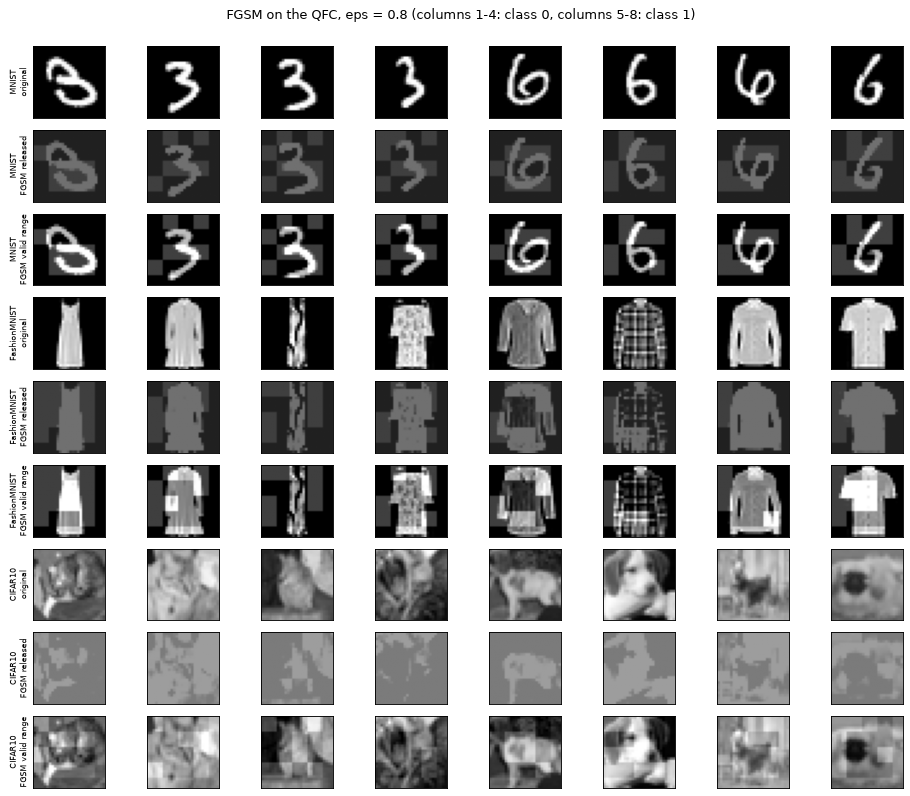

In [17]:
fig, ax = plt.subplots(3 * len(DATASETS), 8, figsize=(12, 3.3 * len(DATASETS) * 1.0), squeeze=False)
for r, name in enumerate(DATASETS):
    d, info = DATA[name], INFO[name]
    seed0 = SEED
    m = MODELS[(name, seed0)]["QFC"]
    Xs, ys = d["test"][0], d["test"][1]
    idx = torch.cat([torch.nonzero(ys == 0)[:4, 0], torch.nonzero(ys == 1)[:4, 0]])
    mean, std = info["mean"], info["std"]
    adv_rel = fgsm(m, Xs[idx], ys[idx], 0.8, 0.0, 1.0); adv_val = fgsm(m, Xs[idx], ys[idx], 0.8, info["lo"], info["hi"])
    to_pix = lambda t: (t * std + mean).squeeze(1).clamp(0, 1).numpy()
    for k in range(8):
        for j, (lab, im) in enumerate((("original", to_pix(Xs[idx])), ("FGSM released", to_pix(adv_rel)), ("FGSM valid range", to_pix(adv_val)))):
            a = ax[3 * r + j, k]; a.imshow(im[k], cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
            if k == 0: a.set_ylabel(f"{name}\n{lab}", fontsize=7)
plt.suptitle("FGSM on the QFC, eps = 0.8 (columns 1-4: class 0, columns 5-8: class 1)", y=1.0); plt.tight_layout(); plt.show()

### 5.3 Adversarial training of the defended models

Section 7 explains and evaluates the adaptive online adversarial training. It is run here, right after the attacks have been defined, so that the defended models exist before the attack grid of Section 6 uses them as targets.

MNIST seed 42 QFC_AT: validation accuracy per epoch [0.846, 0.842, 0.838, 0.843, 0.842, 0.841, 0.847, 0.859, 0.856, 0.855]  (1176 s)


MNIST seed 42 CFC_AT: validation accuracy per epoch [0.996, 0.998, 0.998, 0.998, 1.0, 0.999, 1.0, 0.998, 0.998, 0.998]  (1441 s)
adversarial training finished after 2850 s


,dataset,seed,model,acc,f1
0,MNIST,42,QFC_AT,0.8796,0.8794
1,MNIST,42,CFC_AT,0.9980,0.9980


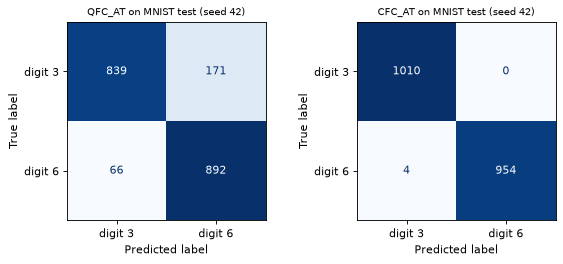

In [18]:
# ---- 5.3 adversarial training (Section 7 explains it); done here so that every target model exists before the attack grid ----
def at_models(name, seed):
    # a fresh model of the same architecture and seed, trained with adaptive online adversarial training (released protocol: [0,1] clamp)
    torch.manual_seed(seed)
    return dict(QFC=QFC(seed=seed), CFC=CFC())

if RUN_AT:
    for s in range(AT_SEEDS):
        seed = SEED + s
        ms = at_models(MAIN, seed)
        for mname, m in ms.items():
            t0 = time.time()
            h = train_model(m, DATA[MAIN], EPOCHS, seed, bs=BS, adv=dict(attacks=AT_ATTACKS, lo=0.0, hi=1.0))
            TRAIN_TIME[(MAIN, seed, mname + "_AT")] = time.time() - t0
            print(f"{MAIN} seed {seed} {mname}_AT: validation accuracy per epoch {np.round(h, 3).tolist()}  ({time.time() - t0:.0f} s)")
        AT_MODELS[(MAIN, seed)] = ms
print("adversarial training finished after %.0f s" % (time.time() - T_START))
if AT_MODELS:
    extra_rows = [clean_row(MAIN, sd, k + "_AT", m) for (_, sd), ms in AT_MODELS.items() for k, m in ms.items()]
    CLEAN = pd.concat([CLEAN, pd.DataFrame(extra_rows)], ignore_index=True)
    display(pd.DataFrame(extra_rows).round(4))
    fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.4))
    for a, (k, m) in zip(ax, AT_MODELS[(MAIN, SEED)].items()):
        ConfusionMatrixDisplay(confusion_matrix(DATA[MAIN]["test"][1], predict(m, DATA[MAIN]["test"][0]), labels=[0, 1]), display_labels=[CLASS_NAMES[MAIN][v] for v in INFO[MAIN]["digits"]]).plot(ax=a, colorbar=False, cmap="Blues")
        a.set_title(f"{k}_AT on {MAIN} test (seed {SEED})", fontsize=9)
    plt.tight_layout(); plt.show()

## 6. White-box attacks and transferability (RQ1, RQ2, Table I)

For every **source** model (the one whose gradient crafts the attack), attack, eps and mode we craft the adversarial test images once and evaluate them on every **target** model:
the two clean networks, the two adversarially trained networks (Section 7), and the Random Forest and SVM on the pooled inputs. White-box = source and target are the same model; black-box
= they differ. For every cell we record

* `ASR` (the repository's definition): fraction of the images that the *target* classifies correctly when clean and wrongly when attacked, divided by the number it classifies correctly when clean;
* `ASR_all` (the paper's text): the same count divided by *all* test images;
* the accuracy of the target on the attacked images, from which the accuracy drop (clean accuracy minus attacked accuracy) follows.

The adversarially trained models are used here as **targets of the clean models' attacks (protocol A, as released)** and as **sources of their own adaptive attacks (protocol B)**.

In [19]:
# ---- 6.1 the attack grid ----
def target_fns(name, seed):
    t = {k: (lambda X, m=m: predict(m, X)) for k, m in MODELS[(name, seed)].items()}
    if (name, seed) in AT_MODELS: t.update({k + "_AT": (lambda X, m=m: predict(m, X)) for k, m in AT_MODELS[(name, seed)].items()})
    for k, clf in CLF[name].items(): t[k] = (lambda X, clf=clf: torch.from_numpy(clf.predict(POOL(X))).long())
    return t

def run_grid(name, seed, sources, modes, eps_list, attacks=ATTACK_NAMES):
    d, info = DATA[name], INFO[name]; X, y = d["test"][0], d["test"][1]
    srcs = {**MODELS[(name, seed)], **{k + "_AT": m for k, m in AT_MODELS.get((name, seed), {}).items()}}
    targets = target_fns(name, seed)
    clean = {t: f(X) for t, f in targets.items()}
    rows = []
    for mode in modes:
        lo, hi = (0.0, 1.0) if mode == "released" else (info["lo"], info["hi"])
        for s in sources:
            for ai, atk in enumerate(attacks):
                for ei, eps in enumerate(eps_list):
                    torch.manual_seed(SEED * 1000 + 100 * ai + ei)
                    adv = run_attack(atk, srcs[s], X, y, eps, lo, hi)
                    for t, f in targets.items():
                        p, c = f(adv), clean[t]
                        ok_c = (c == y); succ = (ok_c & (p != y)).float().sum().item()
                        rows.append(dict(dataset=name, seed=seed, mode=mode, source=s, target=t, attack=atk, eps=eps, acc_clean=ok_c.float().mean().item(),
                                         acc_adv=(p == y).float().mean().item(), ASR=100 * succ / max(ok_c.sum().item(), 1), ASR_all=100 * succ / len(y)))
    return rows

GRID = []
for name in DATASETS:
    n_seeds = N_SEEDS if name == MAIN else 1
    for s in range(n_seeds):
        seed = SEED + s
        t0 = time.time()
        clean_src = ["QFC", "CFC"]
        at_src = [k + "_AT" for k in AT_MODELS[(name, seed)]] if (name, seed) in AT_MODELS else []
        eps_rel = EPS_LIST if (name == MAIN and s == 0) else (EPS_OTHER if name == MAIN else EPS_EXTRA)
        GRID += run_grid(name, seed, clean_src, ["released"], eps_rel)                       # released mode = what the paper's code does
        if "valid" in MODES and name == MAIN and s == 0:                                   # CHOICE: sensitivity mode for the first seed of the main dataset
            GRID += run_grid(name, seed, clean_src, ["valid"], EPS_VALID)
        if at_src:
            GRID += run_grid(name, seed, at_src, ["released"], EPS_AT)                       # protocol B: adaptive attacks on the trained models
        print(f"{name:13s} seed {seed}: attack grid done in {time.time() - t0:.0f} s ({len(GRID)} rows so far)")
RES = pd.DataFrame(GRID)
print("grid rows:", len(RES), "| elapsed %.0f s" % (time.time() - T_START))

MNIST         seed 42: attack grid done in 854 s (1260 rows so far)


MNIST         seed 43: attack grid done in 110 s (1380 rows so far)


MNIST         seed 44: attack grid done in 97 s (1500 rows so far)


FashionMNIST  seed 42: attack grid done in 148 s (1660 rows so far)


CIFAR10       seed 42: attack grid done in 309 s (1820 rows so far)
grid rows: 1820 | elapsed 4369 s


### 6.2 ASR against eps in the white-box setting (the paper's Fig. 3)

Each curve is the ASR of one attack on the model that crafted it, averaged over seeds. Top: **released** mode (what the paper's code does); bottom: **valid-range** mode.

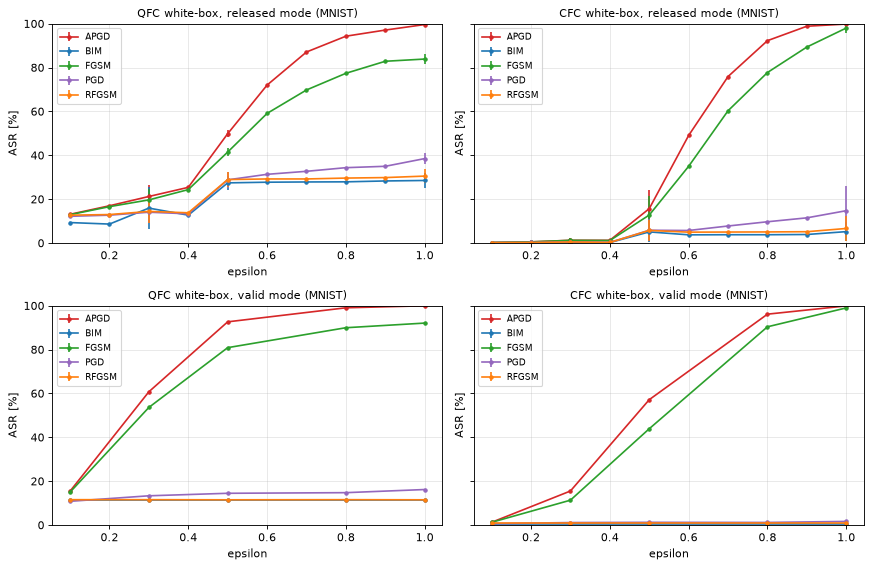

white-box PGD ASR (%), mean +- std over seeds
          released                         valid             
               QFC             CFC           QFC          CFC
0.3  14.03 +- 4.92    0.51 +- 0.53  13.31 +- nan  1.12 +- nan
0.5  28.79 +- 3.59    5.81 +- 4.94  14.46 +- nan  1.22 +- nan
1.0  38.49 +- 2.39  14.73 +- 11.17  16.17 +- nan  1.63 +- nan


In [20]:
colors = dict(APGD="tab:red", BIM="tab:blue", FGSM="tab:green", PGD="tab:purple", RFGSM="tab:orange")
fig, ax = plt.subplots(len(MODES), 2, figsize=(11, 3.6 * len(MODES)), squeeze=False, sharey=True)
for r, mode in enumerate(MODES):
    for c, m in enumerate(["QFC", "CFC"]):
        sub = RES[(RES.dataset == MAIN) & (RES["mode"] == mode) & (RES.source == m) & (RES.target == m)]
        for atk in ATTACK_NAMES:
            g = sub[sub.attack == atk].groupby("eps").ASR.agg(["mean", "std"]).fillna(0)
            ax[r, c].errorbar(g.index, g["mean"], g["std"], marker="o", ms=3, label=atk, color=colors[atk])
        ax[r, c].set_title(f"{m} white-box, {mode} mode ({MAIN})", fontsize=10); ax[r, c].set_xlabel("epsilon"); ax[r, c].set_ylabel("ASR [%]"); ax[r, c].set_ylim(0, 100); ax[r, c].grid(alpha=0.3); ax[r, c].legend(fontsize=8)
plt.tight_layout(); plt.show()

def pgd_asr(model, eps, mode="released"):
    s = RES[(RES.dataset == MAIN) & (RES["mode"] == mode) & (RES.source == model) & (RES.target == model) & (RES.attack == "PGD") & (RES.eps == eps)]
    return s.ASR.mean(), s.ASR.std()
print("white-box PGD ASR (%), mean +- std over seeds")
print(pd.DataFrame({(mode, m): {e: "%.2f +- %.2f" % pgd_asr(m, e, mode) for e in TABLE_EPS if e in EPS_LIST} for mode in MODES for m in ("QFC", "CFC")}))

### 6.3 Transferability (the paper's Table I)

For the four source -> target pairs QFC->QFC, QFC->CFC, CFC->QFC, CFC->CFC: the mean over the five attacks of the ASR and of the accuracy drop at eps = 0.3, 0.5 and 1.0, mean +- std over the seeds.
Rows with the Random Forest and the SVM as targets are our extension (an attack crafted on a gradient model and tested on a model that has no gradient).

In [21]:
def table(df, pairs, mode, field, eps_list=TABLE_EPS):
    out = {}
    for s, t in pairs:
        sub = df[(df.dataset == MAIN) & (df["mode"] == mode) & (df.source == s) & (df.target == t) & df.eps.isin(eps_list)].copy()
        if sub.empty: continue
        sub["val"] = 100 * (sub.acc_clean - sub.acc_adv) if field == "drop" else sub[field]
        per_seed = sub.groupby(["seed", "eps"]).val.mean().unstack("eps")        # mean over the five attacks, per seed
        out[f"{s} -> {t}"] = [(f"{per_seed[e].mean():.2f} +- {per_seed[e].std(ddof=1):.2f} (n={per_seed[e].count()})" if per_seed[e].count() > 1 else f"{per_seed[e].mean():.2f} (n=1)") if e in per_seed else "-" for e in eps_list]
    return pd.DataFrame(out, index=[f"eps={e}" for e in eps_list]).T

PAIRS = [("QFC", "QFC"), ("QFC", "CFC"), ("CFC", "QFC"), ("CFC", "CFC"), ("QFC", "RF"), ("QFC", "SVC"), ("CFC", "RF"), ("CFC", "SVC")]
for mode in MODES:
    print(f"\n######## {mode} mode ########")
    for field, title in (("ASR", "ASR [%] (repository definition)"), ("ASR_all", "ASR_all [%] (relative to all test images, paper's text)"), ("drop", "accuracy drop [%]")):
        print(f"\n--- {title}, mean over the five attacks ---"); display(table(RES, PAIRS, mode, field))


######## released mode ########

--- ASR [%] (repository definition), mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC,17.04 +- 5.87 (n=3),35.28 +- 2.49 (n=3),56.19 +- 2.21 (n=3)
QFC -> CFC,0.33 +- 0.39 (n=3),1.60 +- 1.79 (n=3),22.81 +- 2.69 (n=3)
CFC -> QFC,11.39 +- 4.95 (n=3),16.70 +- 1.93 (n=3),44.37 +- 4.21 (n=3)
CFC -> CFC,0.74 +- 0.69 (n=3),9.00 +- 6.24 (n=3),44.87 +- 4.22 (n=3)
QFC -> RF,41.05 +- 1.11 (n=3),44.89 +- 1.15 (n=3),47.86 +- 0.13 (n=3)
QFC -> SVC,36.47 +- 0.99 (n=3),43.92 +- 0.98 (n=3),47.39 +- 0.22 (n=3)
CFC -> RF,38.13 +- 0.25 (n=3),41.49 +- 1.88 (n=3),48.64 +- 0.04 (n=3)
CFC -> SVC,33.90 +- 0.33 (n=3),41.14 +- 1.86 (n=3),48.46 +- 0.06 (n=3)



--- ASR_all [%] (relative to all test images, paper's text), mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC,15.08 +- 5.22 (n=3),31.21 +- 2.31 (n=3),49.71 +- 2.13 (n=3)
QFC -> CFC,0.33 +- 0.39 (n=3),1.60 +- 1.78 (n=3),22.73 +- 2.69 (n=3)
CFC -> QFC,10.08 +- 4.39 (n=3),14.78 +- 1.77 (n=3),39.24 +- 3.62 (n=3)
CFC -> CFC,0.74 +- 0.69 (n=3),8.97 +- 6.23 (n=3),44.73 +- 4.24 (n=3)
QFC -> RF,40.78 +- 1.10 (n=3),44.59 +- 1.15 (n=3),47.54 +- 0.13 (n=3)
QFC -> SVC,36.23 +- 0.98 (n=3),43.63 +- 0.98 (n=3),47.08 +- 0.22 (n=3)
CFC -> RF,37.88 +- 0.25 (n=3),41.21 +- 1.87 (n=3),48.32 +- 0.04 (n=3)
CFC -> SVC,33.68 +- 0.33 (n=3),40.87 +- 1.85 (n=3),48.14 +- 0.06 (n=3)



--- accuracy drop [%], mean over the five attacks ---


...

,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC,30.09 (n=1),42.14 (n=1),46.18 (n=1)
QFC -> CFC,0.45 (n=1),1.59 (n=1),12.34 (n=1)
CFC -> QFC,6.58 (n=1),14.63 (n=1),36.01 (n=1)
CFC -> CFC,5.84 (n=1),20.70 (n=1),40.36 (n=1)
QFC -> RF,9.03 (n=1),16.57 (n=1),25.29 (n=1)
QFC -> SVC,4.37 (n=1),10.78 (n=1),20.24 (n=1)
CFC -> RF,16.91 (n=1),25.74 (n=1),38.93 (n=1)
CFC -> SVC,8.62 (n=1),19.04 (n=1),34.74 (n=1)



--- ASR_all [%] (relative to all test images, paper's text), mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC,26.76 (n=1),37.47 (n=1),41.07 (n=1)
QFC -> CFC,0.45 (n=1),1.59 (n=1),12.31 (n=1)
CFC -> QFC,5.85 (n=1),13.01 (n=1),32.02 (n=1)
CFC -> CFC,5.82 (n=1),20.64 (n=1),40.23 (n=1)
QFC -> RF,8.97 (n=1),16.46 (n=1),25.12 (n=1)
QFC -> SVC,4.34 (n=1),10.71 (n=1),20.10 (n=1)
CFC -> RF,16.80 (n=1),25.57 (n=1),38.67 (n=1)
CFC -> SVC,8.57 (n=1),18.91 (n=1),34.51 (n=1)



--- accuracy drop [%], mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC,26.76 (n=1),37.47 (n=1),41.05 (n=1)
QFC -> CFC,0.45 (n=1),1.59 (n=1),12.30 (n=1)
CFC -> QFC,5.69 (n=1),12.78 (n=1),31.51 (n=1)
CFC -> CFC,5.82 (n=1),20.64 (n=1),40.23 (n=1)
QFC -> RF,8.73 (n=1),16.20 (n=1),24.86 (n=1)
QFC -> SVC,4.33 (n=1),10.67 (n=1),19.99 (n=1)
CFC -> RF,16.53 (n=1),25.38 (n=1),38.49 (n=1)
CFC -> SVC,8.55 (n=1),18.88 (n=1),34.43 (n=1)


### 6.4 The other two datasets (white-box, one seed)

The paper shows results for MNIST only. For completeness the same attacks are run against the QFC and CFC trained on Fashion-MNIST (dress vs shirt) and CIFAR-10 (cat vs dog), in released mode, as a
white-box experiment with the mean over the five attacks. There is nothing in the paper to compare with, so this block is descriptive. (Empty in `FAST_MODE`.)

In [22]:
extra = [n for n in DATASETS if n != MAIN]
if not extra: print("FAST_MODE: only MNIST is run.")
for name in extra:
    sub = RES[(RES.dataset == name) & (RES["mode"] == "released") & (RES.source == RES.target) & RES.source.isin(["QFC", "CFC"])]
    t = sub.groupby(["source", "eps"]).ASR.mean().unstack("eps").round(2)
    c = sub.groupby("source").acc_clean.first().round(4)
    print(f"\n{name}: clean test accuracy", c.to_dict(), "| white-box ASR [%], mean over five attacks"); display(t)


FashionMNIST: clean test accuracy {'CFC': 0.9285, 'QFC': 0.723} | white-box ASR [%], mean over five attacks


eps,0.1,0.3,0.5,1.0
source,,,,
CFC,10.26,15.23,29.42,43.07
QFC,15.33,22.53,35.13,50.73



CIFAR10: clean test accuracy {'CFC': 0.5915, 'QFC': 0.507} | white-box ASR [%], mean over five attacks


eps,0.1,0.3,0.5,1.0
source,,,,
CFC,39.29,40.03,40.98,43.69
QFC,54.67,59.84,63.08,67.83


## 7. Adversarial training (RQ3, Fig. 4 and Table II)

The authors' **adaptive online adversarial training**: for every mini-batch (i) a normal gradient step on the clean batch, then (ii) for each attack in a list, the attack is run against the *current* model on that
batch with eps = epoch / total epochs (0.1 in epoch 1, ..., 1.0 in epoch 10) and one more gradient step is taken on the adversarial batch. The repository uses 21 attacks; we use the paper's five, so each batch
gives 1 + 5 optimiser steps. The training itself happened in Section 5.3; here we evaluate it.

Two protocols are shown. **Protocol A (as released)**: the adversarially trained models are tested on adversarial images crafted against the *undefended* models. **Protocol B (adaptive)**: the attacker re-runs
the attack against the adversarially trained model itself, which is the honest test of robustness.

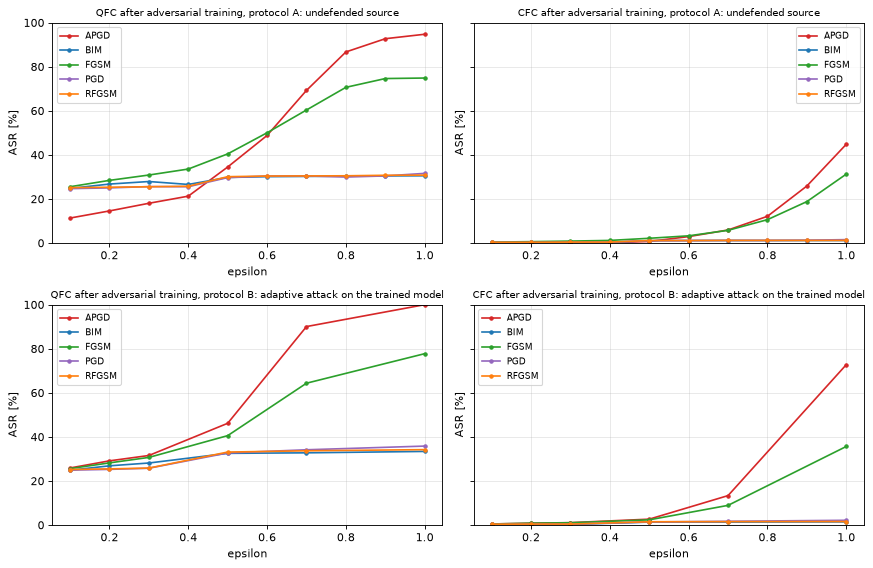

In [23]:
# ---- 7.1 ASR against eps after adversarial training (Fig. 4): protocol A (undefended source) and protocol B (adaptive white-box) ----
if not AT_MODELS:
    print("RUN_AT is False: nothing to show.")
else:
    fig, ax = plt.subplots(2, 2, figsize=(11, 7.2), sharey=True)
    for c, m in enumerate(["QFC", "CFC"]):
        for r, (proto, src) in enumerate((("A: undefended source", m), ("B: adaptive attack on the trained model", m + "_AT"))):
            sub = RES[(RES.dataset == MAIN) & (RES["mode"] == "released") & (RES.source == src) & (RES.target == m + "_AT")]
            for atk in ATTACK_NAMES:
                g = sub[sub.attack == atk].groupby("eps").ASR.mean()
                ax[r, c].plot(g.index, g.values, marker="o", ms=3, label=atk, color=colors[atk])
            ax[r, c].set_title(f"{m} after adversarial training, protocol {proto}", fontsize=9); ax[r, c].set_xlabel("epsilon"); ax[r, c].set_ylabel("ASR [%]"); ax[r, c].set_ylim(0, 100); ax[r, c].grid(alpha=0.3); ax[r, c].legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [24]:
# ---- 7.2 Table II ----
if AT_MODELS:
    AT_PAIRS_A = [("QFC", "QFC_AT"), ("QFC", "CFC_AT"), ("CFC", "QFC_AT"), ("CFC", "CFC_AT")]
    AT_PAIRS_B = [("QFC_AT", "QFC_AT"), ("QFC_AT", "CFC_AT"), ("CFC_AT", "QFC_AT"), ("CFC_AT", "CFC_AT")]
    for proto, pairs in (("A (as released: attacks crafted on the undefended models)", AT_PAIRS_A), ("B (adaptive: attacks crafted on the adversarially trained source)", AT_PAIRS_B)):
        for field, title in (("ASR", "ASR [%]"), ("drop", "accuracy drop [%]")):
            print(f"\n--- protocol {proto}: {title}, mean over the five attacks ---")
            display(table(RES, pairs, "released", field))
    # before / after for the white-box PGD at eps 0.5 and 1.0 on the AT seed(s)
    seeds_at = sorted({s for (_, s) in AT_MODELS})
    ba = {}
    for m in ("QFC", "CFC"):
        for e in (0.5, 1.0):
            pre = RES[(RES.seed.isin(seeds_at)) & (RES.dataset == MAIN) & (RES["mode"] == "released") & (RES.source == m) & (RES.target == m) & (RES.attack == "PGD") & (RES.eps == e)].ASR.mean()
            postA = RES[(RES.seed.isin(seeds_at)) & (RES.dataset == MAIN) & (RES["mode"] == "released") & (RES.source == m) & (RES.target == m + "_AT") & (RES.attack == "PGD") & (RES.eps == e)].ASR.mean()
            postB = RES[(RES.seed.isin(seeds_at)) & (RES.dataset == MAIN) & (RES["mode"] == "released") & (RES.source == m + "_AT") & (RES.target == m + "_AT") & (RES.attack == "PGD") & (RES.eps == e)].ASR.mean()
            ba[(m, e)] = dict(before=pre, after_protocol_A=postA, after_protocol_B=postB)
    print("\nPGD ASR [%] before / after adversarial training"); display(pd.DataFrame(ba).T.round(2))


--- protocol A (as released: attacks crafted on the undefended models): ASR [%], mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC_AT,25.58 (n=1),32.89 (n=1),52.50 (n=1)
QFC -> CFC_AT,0.18 (n=1),0.54 (n=1),2.85 (n=1)
CFC -> QFC_AT,20.52 (n=1),23.70 (n=1),53.13 (n=1)
CFC -> CFC_AT,0.37 (n=1),1.21 (n=1),15.98 (n=1)



--- protocol A (as released: attacks crafted on the undefended models): accuracy drop [%], mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC -> QFC_AT,17.07 (n=1),24.63 (n=1),42.73 (n=1)
QFC -> CFC_AT,0.10 (n=1),0.46 (n=1),2.78 (n=1)
CFC -> QFC_AT,12.32 (n=1),15.92 (n=1),43.00 (n=1)
CFC -> CFC_AT,0.26 (n=1),1.15 (n=1),15.88 (n=1)



--- protocol B (adaptive: attacks crafted on the adversarially trained source): ASR [%], mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC_AT -> QFC_AT,28.39 (n=1),37.01 (n=1),56.23 (n=1)
QFC_AT -> CFC_AT,0.17 (n=1),0.41 (n=1),3.03 (n=1)
CFC_AT -> QFC_AT,19.76 (n=1),18.90 (n=1),31.23 (n=1)
CFC_AT -> CFC_AT,0.63 (n=1),1.83 (n=1),22.71 (n=1)



--- protocol B (adaptive: attacks crafted on the adversarially trained source): accuracy drop [%], mean over the five attacks ---


,eps=0.3,eps=0.5,eps=1.0
QFC_AT -> QFC_AT,19.57 (n=1),28.87 (n=1),46.51 (n=1)
QFC_AT -> CFC_AT,0.08 (n=1),0.32 (n=1),2.96 (n=1)
CFC_AT -> QFC_AT,11.50 (n=1),11.37 (n=1),22.71 (n=1)
CFC_AT -> CFC_AT,0.55 (n=1),1.77 (n=1),22.60 (n=1)



PGD ASR [%] before / after adversarial training


before  after_protocol_A  after_protocol_B
QFC 0.5   29.03             29.69             32.70
    1.0   37.94             31.60             35.82
CFC 0.5    4.38              1.02              1.37
    1.0   13.56              1.53              2.14

## 8. Paper versus notebook

Every number the paper prints is set next to the notebook's. Tolerances: a value is **reproduced** if it is within 2 percentage points (accuracy) or 5 percentage points (ASR and accuracy drop, which are
averages of stochastic attacks on a differently drawn random circuit); otherwise it is **not reached** / **exceeded** with the gap. Qualitative claims get a verdict from the sign or ordering that the notebook measures.
The main comparison uses the **released** mode.

**Two readings of the "Source -> Target" labels of Tables I and II.** The paper's prose says the *source* model crafts the images and the *target* model is evaluated. The authors' result files, however,
name their columns the other way round (`Source_Model` is the model that is **evaluated**, `Target_Model` the one whose gradient **crafted** the images), and the tables may have been copied from those files. The paper
cannot settle which reading is right, so every Table I/II cell is compared twice: *as labelled* (source crafts) and *swapped* (the paper's "source" is the evaluated model). Single-model numbers (clean accuracy, white-box PGD) do not depend on this.

In [25]:
P_T1_ASR  = {("QFC","QFC"): (24.46, 41.83, 60.96), ("QFC","CFC"): (17.83, 19.88, 38.60), ("CFC","QFC"): (0.39, 0.81, 13.32), ("CFC","CFC"): (0.78, 6.85, 43.93)}
P_T1_DROP = {("QFC","QFC"): (14.65, 33.76, 54.75), ("QFC","CFC"): (7.92, 10.85, 31.74), ("CFC","QFC"): (-0.19, 0.39, 12.89), ("CFC","CFC"): (0.16, 6.50, 43.49)}
P_T2_ASR  = {("QFC","QFC"): (15.13, 31.56, 51.20), ("QFC","CFC"): (12.32, 14.88, 35.55), ("CFC","QFC"): (0.23, 0.22, 5.06), ("CFC","CFC"): (0.19, 0.53, 11.01)}
P_T2_DROP = {("QFC","QFC"): (7.89, 24.68, 46.36), ("QFC","CFC"): (4.30, 7.11, 29.34), ("CFC","QFC"): (-0.40, -0.31, 4.85), ("CFC","CFC"): (-0.39, -0.13, 10.18)}
TOL_ACC, TOL_ASR = 2.0, 5.0

def nb_value(src, tgt, eps, field, mode="released", at=False):
    sub = RES[(RES.dataset == MAIN) & (RES["mode"] == mode) & (RES.source == src) & (RES.target == tgt) & (RES.eps == eps)]
    if sub.empty: return np.nan
    v = (100 * (sub.acc_clean - sub.acc_adv)) if field == "drop" else sub[field]
    return v.groupby(sub.seed).mean().mean()          # mean over attacks (and rows), then over seeds

def verdict(paper, ours, tol):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.1f})" if gap > 0 else f"not reached ({gap:.1f})")

rows = []
NAN = float("nan")
acc = CLEAN[(CLEAN.dataset == MAIN)].groupby("model").acc.mean()
rows.append(("Sec. V-A: clean accuracy QFC", 0.909, acc.get("QFC", NAN), verdict(90.9, 100 * acc.get("QFC", np.nan), TOL_ACC), NAN, "-"))
rows.append(("Sec. V-A: clean accuracy CFC", 0.994, acc.get("CFC", NAN), verdict(99.4, 100 * acc.get("CFC", np.nan), TOL_ACC), NAN, "-"))
for m, vals in (("QFC", (35.12, 45.19)), ("CFC", (4.64, 10.15))):
    for e, pv in zip((0.5, 1.0), vals):
        if e in EPS_LIST:
            ov = RES[(RES.dataset == MAIN) & (RES["mode"] == "released") & (RES.source == m) & (RES.target == m) & (RES.attack == "PGD") & (RES.eps == e)].ASR.mean()
            rows.append((f"Sec. V-B: white-box PGD ASR {m}, eps={e} [%]", pv, ov, verdict(pv, ov, TOL_ASR), NAN, "-"))
# Tables I and II: two readings of the paper's "Source -> Target" labels.
#   as labelled : source = model that crafts the images, target = model that is evaluated (the paper's prose)
#   swapped     : the paper's "Source" column is the evaluated model and "Target" the crafting model (the repository's CSV columns are named that way)
for tag, table_p, field, at in (("Table I(a) ASR", P_T1_ASR, "ASR", False), ("Table I(b) acc. drop", P_T1_DROP, "drop", False),
                                ("Table II(a) ASR (protocol A)", P_T2_ASR, "ASR", True), ("Table II(b) acc. drop (protocol A)", P_T2_DROP, "drop", True)):
    if at and not AT_MODELS: continue
    for (s, t), vals in table_p.items():
        for e, pv in zip(TABLE_EPS, vals):
            if e in EPS_LIST:
                if not at:
                    ov, os_ = nb_value(s, t, e, field), nb_value(t, s, e, field)
                else:
                    ov, os_ = nb_value(s, t + "_AT", e, field), nb_value(t, s + "_AT", e, field)
                rows.append((f"{tag}: {s}->{t}, eps={e} [%]", pv, ov, verdict(pv, ov, TOL_ASR), os_, verdict(pv, os_, TOL_ASR)))
CMP = pd.DataFrame(rows, columns=["claim", "paper", "notebook (as labelled)", "verdict (as labelled)", "notebook (swapped)", "verdict (swapped)"])
for c in ("paper", "notebook (as labelled)", "notebook (swapped)"): CMP[c] = pd.to_numeric(CMP[c], errors="coerce").round(3)
pd.set_option("display.max_rows", 200, "display.width", 250, "display.max_colwidth", 70)
display(CMP)
tab = CMP[CMP.claim.str.startswith("Table")]
for col in ("verdict (as labelled)", "verdict (swapped)"):
    print(f"{col:24s}: Tables I and II ({len(tab)} cells):", tab[col].str.split(" ").str[0].value_counts().to_dict())
print("all rows, as labelled   :", CMP["verdict (as labelled)"].str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook (as labelled),verdict (as labelled),notebook (swapped),verdict (swapped)
0,Sec. V-A: clean accuracy QFC,0.909,0.884,not reached (-2.5),NaN,-
1,Sec. V-A: clean accuracy CFC,0.994,0.997,reproduced,NaN,-
2,"Sec. V-B: white-box PGD ASR QFC, eps=0.5 [%]",35.120,28.792,not reached (-6.3),NaN,-
3,"Sec. V-B: white-box PGD ASR QFC, eps=1.0 [%]",45.190,38.487,not reached (-6.7),NaN,-
4,"Sec. V-B: white-box PGD ASR CFC, eps=0.5 [%]",4.640,5.809,reproduced,NaN,-
5,"Sec. V-B: white-box PGD ASR CFC, eps=1.0 [%]",10.150,14.727,reproduced,NaN,-
6,"Table I(a) ASR: QFC->QFC, eps=0.3 [%]",24.460,17.038,not reached (-7.4),17.038,not reached (-7.4)
7,"Table I(a) ASR: QFC->QFC, eps=0.5 [%]",41.830,35.283,not reached (-6.5),35.283,not reached (-6.5)
8,"Table I(a) ASR: QFC->QFC, eps=1.0 [%]",60.960,56.192,reproduced,56.192,reproduced
9,"Table I(a) ASR: QFC->CFC, eps=0.3 [%]",17.830,0.333,not reached (-17.5),11.389,not reached (-6.4)


verdict (as labelled)   : Tables I and II (48 cells): {'reproduced': 19, 'exceeded': 15, 'not': 14}
verdict (swapped)       : Tables I and II (48 cells): {'reproduced': 31, 'exceeded': 13, 'not': 4}
all rows, as labelled   : {'reproduced': 22, 'not': 17, 'exceeded': 15}


In [26]:
# ---- 8.2 the qualitative claims (RQ1, RQ2, RQ3) tested from the notebook's own numbers ----
def A(src, tgt, mode="released", eps_list=TABLE_EPS, atk=None, field="ASR"):
    sub = RES[(RES.dataset == MAIN) & (RES["mode"] == mode) & (RES.source == src) & (RES.target == tgt) & RES.eps.isin(eps_list)]
    if atk: sub = sub[sub.attack == atk]
    return sub[field].mean()

claims = []
for mode in MODES:
    q, c = A("QFC", "QFC", mode, [e for e in (0.5, 1.0) if e in EPS_LIST], "PGD"), A("CFC", "CFC", mode, [e for e in (0.5, 1.0) if e in EPS_LIST], "PGD")
    claims.append((f"RQ1 [{mode}]: white-box PGD ASR(QFC) > ASR(CFC)", f"QFC {q:.1f} % vs CFC {c:.1f} %", "reproduced" if q > c else "not reproduced"))
    a1, a2 = A("QFC", "CFC", mode), A("CFC", "QFC", mode)
    claims.append((f"RQ2 [{mode}]: QFC->CFC transfers better than CFC->QFC (as labelled: crafted on QFC, tested on CFC)", f"QFC->CFC {a1:.1f} % vs CFC->QFC {a2:.1f} %", "reproduced" if a1 > a2 else "not reproduced"))
    claims.append((f"RQ2 [{mode}]: same claim, paper's labels read as the repository's CSV columns (evaluated -> crafting model)", f"images crafted on CFC, tested on QFC {a2:.1f} % vs crafted on QFC, tested on CFC {a1:.1f} %", "reproduced" if a2 > a1 else "not reproduced"))
    wq, wc = A("QFC", "QFC", mode), A("CFC", "CFC", mode)
    claims.append((f"Sec. V-C [{mode}]: transfer to the other model is weaker than white-box (QFC->CFC < QFC->QFC)", f"{a1:.1f} % vs {wq:.1f} %", "reproduced" if a1 < wq else "not reproduced"))
    f_, a_, p_, b_ = (A("QFC", "QFC", mode, [1.0], x) for x in ("FGSM", "APGD", "PGD", "BIM"))
    claims.append((f"Fig. 3 [{mode}]: FGSM and APGD (full budget) beat PGD and BIM at eps = 1 on the QFC", f"FGSM {f_:.0f}, APGD {a_:.0f} vs PGD {p_:.0f}, BIM {b_:.0f} %", "reproduced" if min(f_, a_) > max(p_, b_) else "not reproduced"))
if AT_MODELS:
    for proto, srcs in (("A", ("QFC", "CFC")), ("B", ("QFC_AT", "CFC_AT"))):
        qb = A("QFC", "QFC", "released", [0.5, 1.0]); qa = A(srcs[0], "QFC_AT", "released", [0.5, 1.0])
        cb = A("CFC", "CFC", "released", [0.5, 1.0]); ca = A(srcs[1], "CFC_AT", "released", [0.5, 1.0])
        qrel, crel = 100 * (qb - qa) / qb, 100 * (cb - ca) / cb
        claims.append((f"RQ3 [protocol {proto}]: adversarial training helps CFC much more than QFC (relative ASR reduction, mean of eps 0.5 and 1.0)",
                       f"QFC {qb:.1f} -> {qa:.1f} % ({qrel:+.0f} %), CFC {cb:.1f} -> {ca:.1f} % ({crel:+.0f} %)", "reproduced" if crel > qrel + 10 else "not reproduced"))
QUAL = pd.DataFrame(claims, columns=["claim", "notebook measurement", "verdict"]); display(QUAL)

,claim,notebook measurement,verdict
0,RQ1 [released]: white-box PGD ASR(QFC) > ASR(CFC),QFC 33.6 % vs CFC 10.3 %,reproduced
1,RQ2 [released]: QFC->CFC transfers better than CFC->QFC (as labell...,QFC->CFC 8.2 % vs CFC->QFC 24.2 %,not reproduced
2,"RQ2 [released]: same claim, paper's labels read as the repository'...","images crafted on CFC, tested on QFC 24.2 % vs crafted on QFC, tes...",reproduced
3,Sec. V-C [released]: transfer to the other model is weaker than wh...,8.2 % vs 36.2 %,reproduced
4,Fig. 3 [released]: FGSM and APGD (full budget) beat PGD and BIM at...,"FGSM 84, APGD 100 vs PGD 38, BIM 29 %",reproduced
5,RQ1 [valid]: white-box PGD ASR(QFC) > ASR(CFC),QFC 15.3 % vs CFC 1.4 %,reproduced
6,RQ2 [valid]: QFC->CFC transfers better than CFC->QFC (as labelled:...,QFC->CFC 4.8 % vs CFC->QFC 19.1 %,not reproduced
7,"RQ2 [valid]: same claim, paper's labels read as the repository's C...","images crafted on CFC, tested on QFC 19.1 % vs crafted on QFC, tes...",reproduced
8,Sec. V-C [valid]: transfer to the other model is weaker than white...,4.8 % vs 39.5 %,reproduced
9,Fig. 3 [valid]: FGSM and APGD (full budget) beat PGD and BIM at ep...,"FGSM 92, APGD 100 vs PGD 16, BIM 11 %",reproduced


## Reading the paper critically

* **The inputs are standardised but the attacks assume [0, 1].** The released code feeds mean/std-normalised images (range about [-0.42, 2.82]) to `torchattacks`, which clamps every adversarial image to [0, 1]. For a standardised image that
  clamp is itself a large perturbation: all background pixels jump from -0.42 to 0 and bright strokes are cut from up to 2.82 to 1. So a part of the ASR the paper reports as "adversarial vulnerability" at small eps is simply the effect of this
  distortion on a model that was trained on the standardised range. The "valid range" mode of this notebook isolates the real, eps-bounded part; the two modes can disagree strongly.
* **eps is not a pixel budget.** eps = 1.0 on standardised MNIST is a pixel budget of 0.31, but because of the clamp above it is not reliably that. BIM, PGD and RFGSM also use a step of 2/255 with 10 steps, so they move a pixel by at most 0.078 whatever eps is: their flat curves
  in Fig. 3 say more about the step size than about robustness. Comparing attacks across eps therefore compares step-size defaults.
* **Quantum versus classical is confounded by accuracy and capacity.** The QFC has 16 inputs (a 6 x 6 pooled image) and about 41 trainable angles, the CFC sees the full image with a 6 x 6 convolution and thousands of weights. A smaller, less accurate model is easier to attack,
  as the authors concede; the Random Forest and SVM on the same 16 pooled inputs in Section 6.3 help to separate "quantum" from "low-resolution input".
* **The transfer direction in Table I is ambiguous.** With the labels read as the prose says (source crafts), our QFC-crafted images barely fool the CFC at eps = 0.3 and 0.5 (about 0.3 % and 1.6 % ASR) while CFC-crafted images fool the QFC much more (about 11 % and 17 %), the opposite of the paper's
  "QFC->CFC transfers better". With the labels read as the authors' result files name them (swapped), our numbers match the paper's Table I(a) closely (see the *swapped* columns of Section 8 and the measured pairs in Section 6.3). The simplest explanation is that the table inherited the repository's column names; we cannot prove it. Either way the paper's statement "QFC is more resilient to black-box transfer" needs care: which direction is meant changes the conclusion.
* **A strong classical model on the same 16 inputs beats the QFC.** The Random Forest and the RBF-SVM trained on the very 16 pooled values that the QFC encodes reach about 99.3 % on MNIST 3 vs 6, against about 88.5 % for the QFC (Section 4.4). The QFC's lower accuracy, and part of its higher vulnerability, is therefore a property of this small quantum circuit with a fixed encoding, not of the low-resolution input. The same two models are also fooled by the transferred attacks (Section 6.3), so "low-resolution inputs are easy to attack" is a competing explanation to "quantum models are vulnerable".
* **One random circuit, one seed.** The QFC contains a random 50-gate layer. The paper reports one draw and one seed; this notebook shows that different draws give different accuracies and ASRs (see the seed spread in the tables), so differences of a few points are not meaningful.
* **Adversarial training: no gain for the QFC, a large one for the CFC (on one seed).** In our run the adversarially trained QFC is attacked as successfully as the undefended one (PGD ASR at eps = 1.0 about 38 % before, 32 % and 36 % after under protocols A and B), while the CFC's PGD ASR drops from about 14 % to about 2 %; the
  strong attacks (APGD, FGSM) still succeed at large eps on the defended CFC under the adaptive protocol B. This agrees in direction with RQ3, but it rests on a single adversarial-training seed and on five rather than 21 training attacks.
* **Adversarial training as evaluated in the code is not an adaptive test.** The released evaluation attacks the *undefended* networks and feeds those images to the defended ones. That measures how much defended models resist old attacks, not how they resist a new attack
  (protocol B). The paper's conclusion that adversarial training "barely helps" the QFC may therefore be even more pessimistic under a proper adaptive attack, or not; the two protocols can be compared above.
* **Simulation only.** Exact expectation values, no shot noise, no hardware noise. The attacks use back-propagation through the simulator, which a real device would not offer (only parameter-shift gradients with the same cost per parameter, but the input gradient needs the
  classical pooling and encoding differentiated analytically, which is possible here).
* **Cybersecurity relevance.** Images are only a benchmark; the authors point to intrusion detection (their previous CAN-bus study) as the intended application. The 16-number input of the QFC is similar in size to a feature vector of network flows, so the same pipeline can be applied to tabular security data.

## Exercises

1. **Seeds and circuits.** Set `N_SEEDS = 5` and look at the spread of the QFC clean accuracy and white-box ASR. How much of the "QFC is more vulnerable" gap is larger than the spread across random circuits?
2. **Equal capacity.** Replace the CFC by a small network that also sees only the 16 pooled values (for example `Linear(16, 8)-ReLU-Linear(8, 2)`), train it, and repeat the white-box study. Does the quantum model remain more vulnerable?
3. **A proper step size.** Give BIM and PGD a step `alpha = eps / 4` (instead of 2/255) in valid-range mode and redraw Fig. 3. Do they now beat FGSM at large eps?
4. **Adaptive adversarial training.** Train the QFC with only PGD (`AT_ATTACKS = ["PGD"]`) in valid-range mode (`lo, hi = INFO[MAIN]["lo"], INFO[MAIN]["hi"]` in `train_model`'s `adv` dictionary) and evaluate it with protocol B. Does robustness appear?
5. **Another task.** Use digits (1, 7) or the Fashion-MNIST classes (T-shirt, coat) by changing `DIGITS` in the data cell; are the QFC vs CFC conclusions stable across tasks?

In [27]:
print("total runtime of this notebook run: %.1f minutes (FAST_MODE=%s)" % ((time.time() - T_START) / 60, FAST_MODE))

total runtime of this notebook run: 73.0 minutes (FAST_MODE=False)
